## Hydrodynamic model of the Southern North Sea

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch
import optuna
import ast


# dataset helper
from helper import get_wl_point_obs, extract_water_level_measurements

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

# Importing modules from src
from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED
from src.utils import plot_training_curves, evaluate_model

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Data Loading

In [3]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/Mesh_8000_elems_HD_v2.mesh"
obs_fldr = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)
geom = dfs.geometry

# load simulation
ds = dfs.read(time=slice("2022-01-01", "2023-10-30"))
valid_nodes = ~np.isnan(ds["Surface elevation"].values).any(axis=0)
H, U, V = [
    torch.tensor(ds[var].values[:, valid_nodes], dtype=torch.float32)
    for var in ("Surface elevation", "U velocity", "V velocity")
]
print("Simulation data loaded successfully.")

# load observations
high_fidelity = {"Dover", "ZeebruggeWielingendok", "NWA", "K141"}
stations = [obs for obs in get_wl_point_obs() if obs.name in high_fidelity]
measurements = torch.tensor(
    extract_water_level_measurements(stations, ds_time=ds.time, obs_fldr=obs_fldr),
    dtype=torch.float32,
)
print("Observation data loaded successfully.\n")

# print array shapes
for name, x in {"H": H, "U": U, "V": V, "Measurements": measurements}.items():
    print(f"{name} shape:", x.shape, ".\tNumber of NaNs:", torch.isnan(x).sum().item())

del dfs

Simulation data loaded successfully.
Observation data loaded successfully.

H shape: torch.Size([32064, 8533]) .	Number of NaNs: 0
U shape: torch.Size([32064, 8533]) .	Number of NaNs: 0
V shape: torch.Size([32064, 8533]) .	Number of NaNs: 0
Measurements shape: torch.Size([32064, 4]) .	Number of NaNs: 25037


## Hyperparameters

In [4]:
##########################################################################################################
################## FIXED HYPERPARAMETERS FOR TUNING RUNS #################################################
##########################################################################################################
ERRORS = []

# DataManager
LAGS = 48               # number of past time steps to use as input for the model
TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing
COMPRESS_H = 12         # modes kept for H (surface elevation)
COMPRESS_U = 40         # modes kept for U (U velocity)
COMPRESS_V = 68         # modes kept for V (V velocity)
MASKING_TYPE = "mask_data"  # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 1e-3    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)
BATCH_SIZE = 32         # batch size for training
PATIENCE = 40           # number of epochs with no improvement on validation loss before stopping training

##########################################################################################################
################## GRID OF HYPERPARAMETERS TO TUNE #######################################################
##########################################################################################################

# Architecture
TRANSFORMER_TYPE = ["transformer", "transformer_hidden_mask", "transformer_attn_mask", "transformer_learned_mask"]  
DOUBLE_CHANNEL = [True, False]                  # whether to use double channel input (H,U,V) or single channel (H only)
MAX_ENCODER_DEPTH = 4                           # number of encoder layers
HIDDEN_SIZE = [16,32,48,64]                        # hidden size for encoder and decoder layers
N_HEADS = 4                                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = [32,48,64,128]                   # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = ["cnn","mlp"]                         # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = ["64", "64,96", "96"]    # sampled as strings; parsed to int list in create_model
MAX_DROPOUT = 0.2                               # dropout rate for encoder and decoder layers

N_OPTUNA_TRIALS = 100  # number of Optuna trials to run for hyperparameter tuning

print("Total number of hyperparameter combinations to explore:", len(TRANSFORMER_TYPE) * len(DOUBLE_CHANNEL) * len(HIDDEN_SIZE) * len(DIM_FEEDFORWARD) * len(DECODER) * len(DECODER_HIDDEN_SIZES) * 4 * 3)

Total number of hyperparameter combinations to explore: 9216


## DataManager

In [5]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements)
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]


Data shapes after preparation:
Train:	 torch.Size([25651, 48, 4]) -> torch.Size([25651, 120])
Val:	 torch.Size([3206, 48, 4]) -> torch.Size([3206, 120])
Test:	 torch.Size([3207, 48, 4]) -> torch.Size([3207, 120])


## Training

In [6]:
# create model from Optuna trial
def create_model(trial):
    return dict(
        encoder              = trial.suggest_categorical('encoder', TRANSFORMER_TYPE),
        double_channels      = trial.suggest_categorical('double_channels', DOUBLE_CHANNEL),
        encoder_depth        = trial.suggest_int('encoder_depth', 1, MAX_ENCODER_DEPTH),
        n_heads              = N_HEADS,
        dim_feedforward      = trial.suggest_categorical('dim_feedforward', DIM_FEEDFORWARD),
        hidden_size          = trial.suggest_categorical('hidden_size', HIDDEN_SIZE),
        input_length         = LAGS,
        decoder              = trial.suggest_categorical('decoder', DECODER),
        decoder_hidden_sizes = [int(x) for x in trial.suggest_categorical('decoder_hidden_sizes', DECODER_HIDDEN_SIZES).split(',')],
        dropout              = trial.suggest_float('dropout', 0.0, MAX_DROPOUT, step=0.1),
        input_size           = nn_input_shape,
        output_size          = nn_output_shape,
    )

# objective function for Optuna to minimize (validation loss)
def objective(trial):

    # create model from trial hyperparameters
    model_args = create_model(trial)
    mshred = mSHRED(args=model_args).to(device)
    
    # fit model and get training and validation losses
    _ , valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=False,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE, masking_type=MASKING_TYPE,
    )

    # Evaluating model on test set using the best model from training (early stopping)
    test_error = evaluate_model(
        evaluate, mshred, train_dataset, val_dataset, test_dataset,
        model=f"(mSHRED)", type=f"{model_args}", masking_type=MASKING_TYPE
    )

    # Logging errors and disply the last row
    ERRORS.append(test_error)                   # log test error for current trial
    dataframe_errors = pd.DataFrame(ERRORS)     # create dataframe from logged errors
    #display(dataframe_errors.tail(1))          # display last row of errors dataframe
    dataframe_errors.to_csv('dataframe_errors_optuna.csv', index=False)     # save errors to csv after each trial

    # return validation error for Optuna to minimize
    return float(test_error["val-mse"])

In [ ]:
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=N_OPTUNA_TRIALS)

[I 2026-05-10 20:41:24,080] A new study created in memory with name: no-name-c2c5ed4a-e9f9-43a6-992a-e33cdd20af79


[I 2026-05-10 20:44:56,547] Trial 0 finished with value: 0.004277291672719097 and parameters: {'encoder': 'transformer_attn_mask', 'double_channels': False, 'encoder_depth': 1, 'dim_feedforward': 64, 'hidden_size': 64, 'decoder': 'cnn', 'decoder_hidden_sizes': '96', 'dropout': 0.0}. Best is trial 0 with value: 0.004277291672719097.
[I 2026-05-10 21:12:14,593] Trial 1 finished with value: 0.00413233823632718 and parameters: {'encoder': 'transformer', 'double_channels': False, 'encoder_depth': 4, 'dim_feedforward': 48, 'hidden_size': 48, 'decoder': 'mlp', 'decoder_hidden_sizes': '96', 'dropout': 0.1}. Best is trial 1 with value: 0.00413233823632718.
[I 2026-05-10 21:33:52,632] Trial 2 finished with value: 0.004158779725906481 and parameters: {'encoder': 'transformer_attn_mask', 'double_channels': False, 'encoder_depth': 2, 'dim_feedforward': 32, 'hidden_size': 16, 'decoder': 'cnn', 'decoder_hidden_sizes': '96', 'dropout': 0.1}. Best is trial 1 with value: 0.00413233823632718.
[I 2026-05-

## Results

In [34]:
dataframe_errors = pd.read_csv("dataframe_errors_optuna.csv")
dataframe_errors = dataframe_errors.sort_values(by="val-mre")

# Parse the 'type' column string into a dict and expand into columns
type_df = dataframe_errors['type'].apply(lambda x: ast.literal_eval(x)).apply(pd.Series)
# Remove columns with the same value across all rows
type_df = type_df.drop(columns=['input_size', 'output_size', 'input_length', 'n_heads'])
# Add the val-mre column
type_df['val-mre'] = dataframe_errors['val-mre'].values

print("Dataframe with hyperparameters ordered by test MRE:")
display(type_df.sort_values("val-mre").head(15))

Dataframe with hyperparameters ordered by test MRE:


,encoder,double_channels,encoder_depth,dim_feedforward,hidden_size,decoder,decoder_hidden_sizes,dropout,val-mre
53,transformer_learned_mask,False,4,48,32,cnn,"[64, 96]",0.1,0.125566
1,transformer,False,4,48,48,mlp,[96],0.1,0.125747
51,transformer_learned_mask,False,4,48,32,cnn,"[64, 96]",0.1,0.125771
39,transformer_attn_mask,False,4,48,32,mlp,"[64, 96]",0.1,0.125868
41,transformer_attn_mask,False,4,48,32,mlp,"[64, 96]",0.1,0.125879
43,transformer_attn_mask,False,4,48,32,mlp,"[64, 96]",0.1,0.125887
14,transformer_attn_mask,False,4,48,48,mlp,"[64, 96]",0.1,0.125896
55,transformer_learned_mask,False,4,64,32,cnn,"[64, 96]",0.1,0.125939
46,transformer_learned_mask,False,4,48,32,cnn,"[64, 96]",0.1,0.125954
48,transformer_learned_mask,False,4,48,32,cnn,"[64, 96]",0.1,0.125967


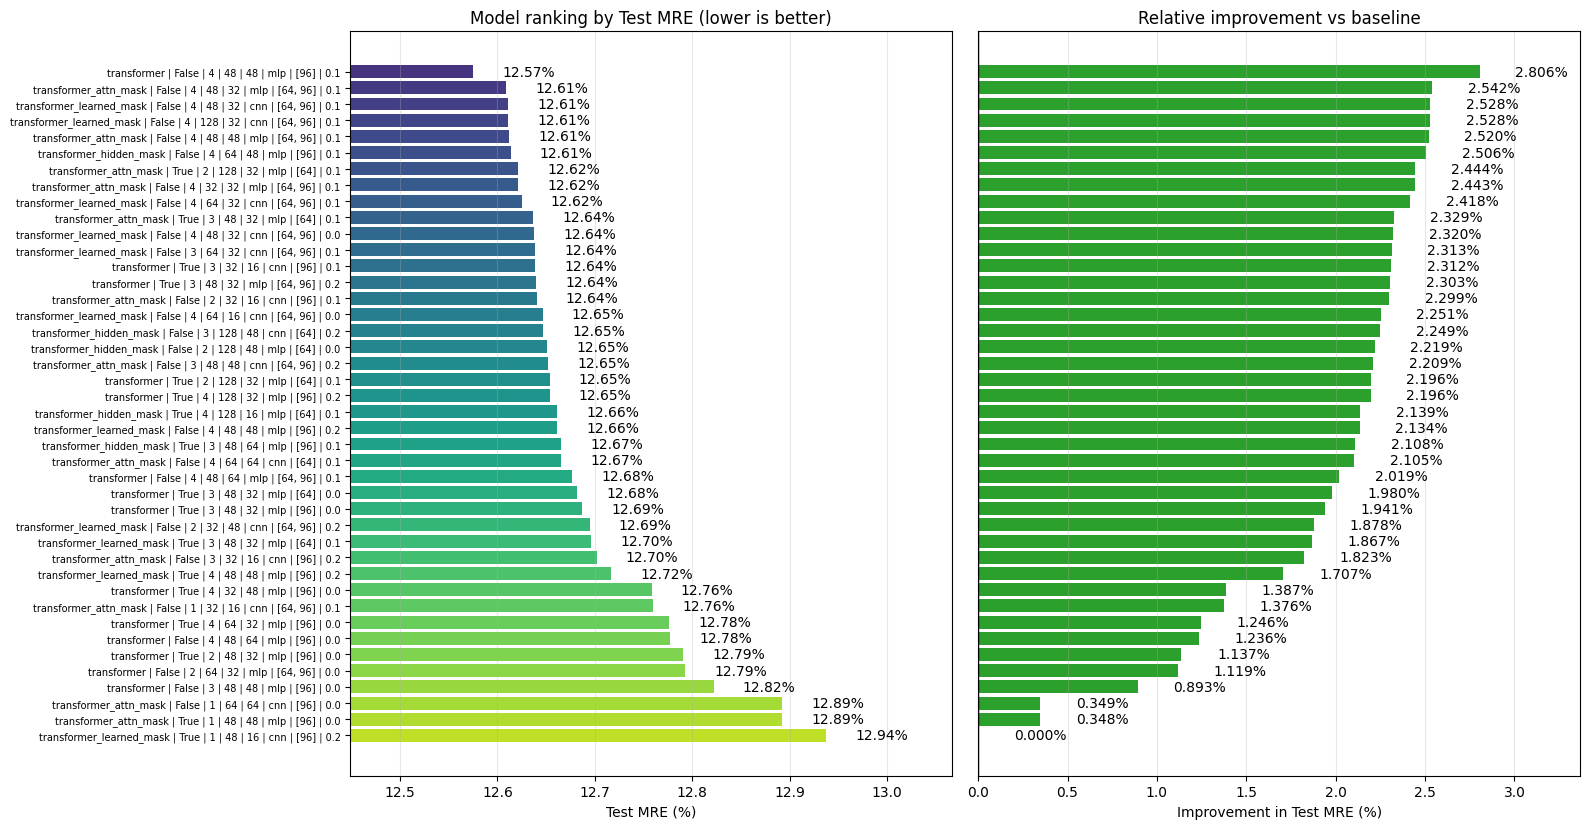

In [35]:
# Convert any list-valued columns to strings so they are hashable for groupby
hyperparam_cols = [c for c in type_df.columns if c != "val-mre"]
for col in hyperparam_cols:
    if type_df[col].apply(lambda x: isinstance(x, list)).any():
        type_df[col] = type_df[col].apply(lambda x: str(x) if isinstance(x, list) else x)

# Average duplicated hyperparameter configurations
df_plot = (
    type_df
    .groupby(hyperparam_cols, as_index=False)["val-mre"]
    .mean()
    .sort_values(by="val-mre")
    .reset_index(drop=True)
)

# Build label from all hyperparameter columns (values only, no keys)
df_plot["label"] = df_plot[hyperparam_cols].apply(
    lambda row: " | ".join(f"{v}" for k, v in row.items()), axis=1
)

df_plot["val-mre_%"] = 100 * df_plot["val-mre"]
baseline_test_mre = df_plot["val-mre"].iloc[-1]
df_plot["improvement_vs_T0_%"] = 100 * (baseline_test_mre - df_plot["val-mre"]) / baseline_test_mre

n = len(df_plot)
fig_height = max(8, n * 0.2)
fig, axes = plt.subplots(1, 2, figsize=(16, fig_height))

# --- Left: Test MRE ranking (with labels) ---
colors = plt.cm.viridis(np.linspace(0.15, 0.9, n))
axes[0].barh(df_plot["label"], df_plot["val-mre_%"], color=colors)
axes[0].invert_yaxis()
axes[0].set_title("Model ranking by Test MRE (lower is better)")
axes[0].set_xlabel("Test MRE (%)")
axes[0].grid(axis="x", alpha=0.3)
axes[0].tick_params(axis="y", labelsize=7)
axes[0].set_xlim(min(df_plot["val-mre_%"]) * 0.99, max(df_plot["val-mre_%"]) * 1.01)

for i, v in enumerate(df_plot["val-mre_%"]):
    axes[0].text(v + 0.03, i, f"{v:.2f}%", va="center", fontsize=10)

# --- Right: Improvement (no y-axis labels) ---
imp_colors = [
    "tab:blue" if "Normal_training" in lbl else ("tab:green" if x >= 0 else "tab:red")
    for lbl, x in zip(df_plot["label"], df_plot["improvement_vs_T0_%"])
]
axes[1].barh(df_plot["label"], df_plot["improvement_vs_T0_%"], color=imp_colors)
axes[1].invert_yaxis()
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Relative improvement vs baseline")
axes[1].set_xlabel("Improvement in Test MRE (%)")
axes[1].grid(axis="x", alpha=0.3)
axes[1].set_xlim(min(df_plot["improvement_vs_T0_%"]) * 1, max(df_plot["improvement_vs_T0_%"]) * 1.2)

# Hide y-axis labels and ticks on the right plot
axes[1].set_yticklabels([])
axes[1].tick_params(axis="y", left=False)

for i, v in enumerate(df_plot["improvement_vs_T0_%"]):
    axes[1].text(v + (0.2 if v >= 0 else -0.6), i, f"{v:.3f}%", va="center", fontsize=10)

plt.tight_layout()
plt.savefig("hyperparams.png", dpi=150, bbox_inches="tight")
plt.show()

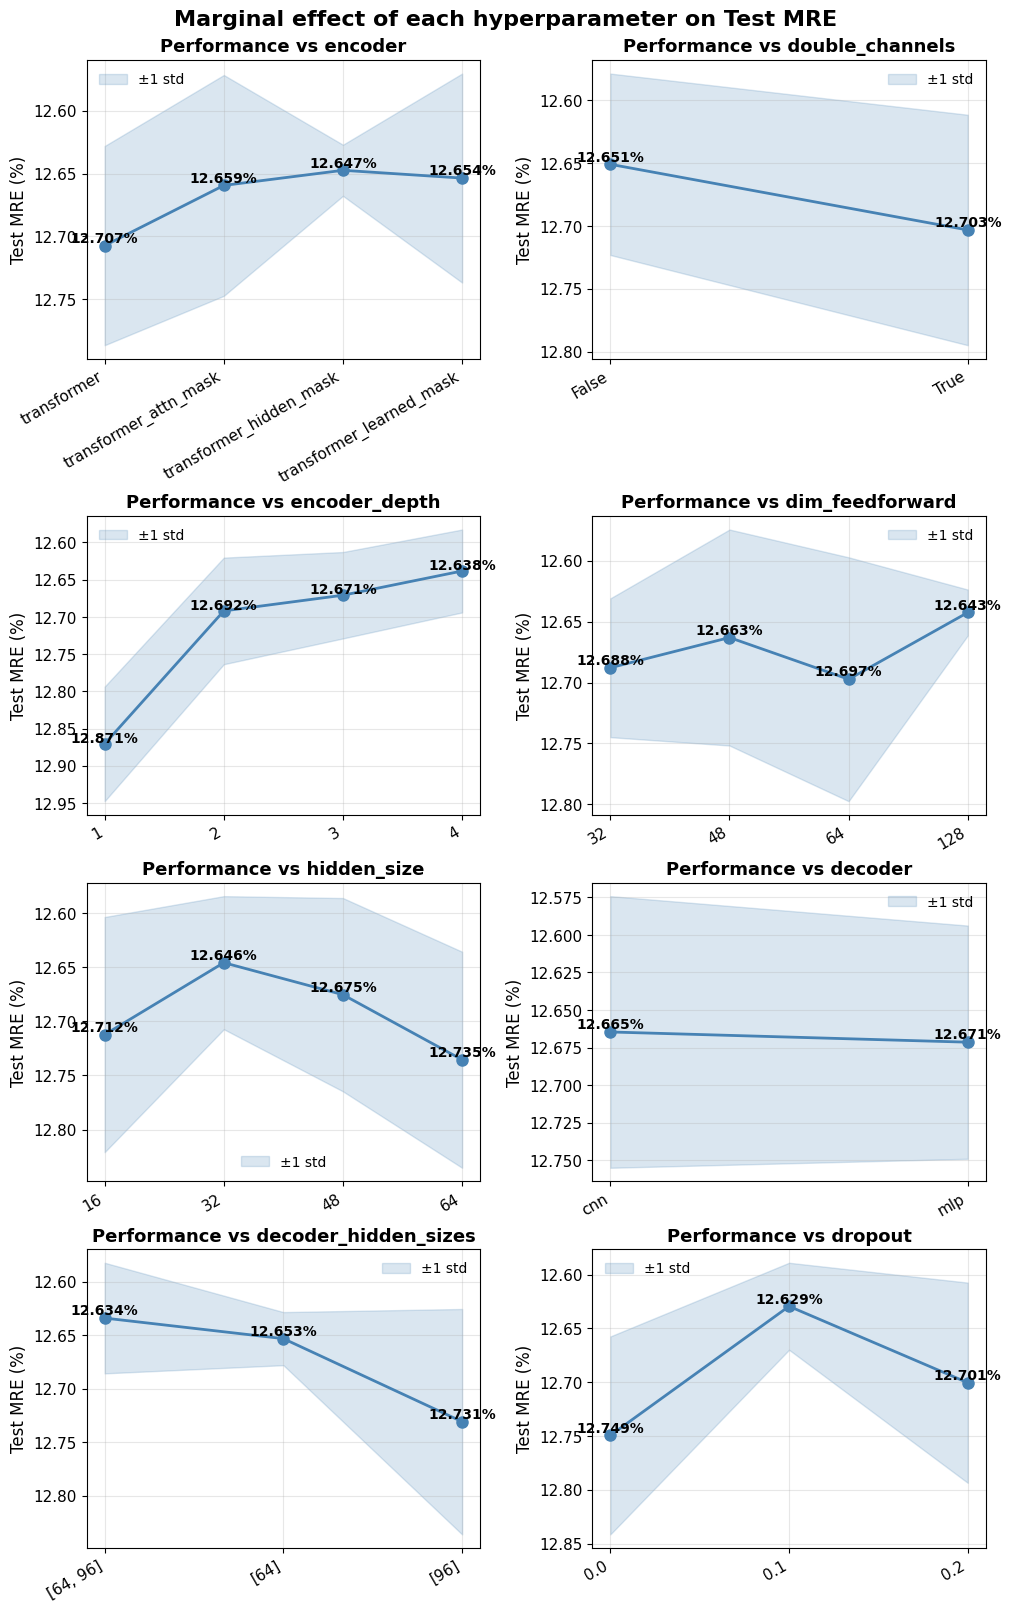

In [36]:
n_rows = 4
n_cols = int(np.ceil(len(hyperparam_cols) / n_rows))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows), constrained_layout=True)
axes = axes.flatten()

for idx, col in enumerate(hyperparam_cols):
    ax = axes[idx]

    perf = type_df.groupby(col)["val-mre"].agg(["mean", "std"]).reset_index()
    perf = perf.sort_values(col)

    x_vals = list(range(len(perf)))

    mean_pct = perf["mean"] * 100
    std_pct  = perf["std"]  * 100

    ax.plot(x_vals, mean_pct, marker="o", linewidth=2, markersize=8, color="steelblue")
    ax.fill_between(
        x_vals,
        mean_pct - std_pct,
        mean_pct + std_pct,
        alpha=0.2, color="steelblue", label="±1 std"
    )

    ax.set_xticks(x_vals)
    ax.set_xticklabels(perf[col].astype(str).tolist(), rotation=30, ha="right", fontsize=11)
    
    ax.set_ylabel("Test MRE (%)", fontsize=12)
    ax.set_title(f"Performance vs {col}", fontsize=13, fontweight="bold")
    ax.tick_params(axis="y", labelsize=11)
    ax.grid(alpha=0.3)
    ax.invert_yaxis()

    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=10, loc="best", frameon=False)

    y_offset = std_pct.max() * 0.03
    for x, (_, row) in zip(x_vals, perf.iterrows()):
        ax.text(x, row["mean"] * 100 - y_offset, f"{row['mean'] * 100:.3f}%",
                ha="center", fontsize=10, fontweight="bold")

for idx in range(len(hyperparam_cols), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle("Marginal effect of each hyperparameter on Test MRE", fontsize=16, fontweight="bold")
plt.savefig("hyperparam_marginal_effects.png", dpi=150, bbox_inches="tight")
plt.show()

## Run 1: lags 24


<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>encoder</th>
      <th>double_channels</th>
      <th>encoder_depth</th>
      <th>dim_feedforward</th>
      <th>hidden_size</th>
      <th>decoder</th>
      <th>decoder_hidden_sizes</th>
      <th>dropout</th>
      <th>val-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>13</th>
      <td>transformer_attn_mask</td>
      <td>True</td>
      <td>3</td>
      <td>48</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64]</td>
      <td>0.1</td>
      <td>0.126443</td>
    </tr>
    <tr>
      <th>22</th>
      <td>transformer_attn_mask</td>
      <td>True</td>
      <td>3</td>
      <td>64</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.126480</td>
    </tr>
    <tr>
      <th>19</th>
      <td>transformer_attn_mask</td>
      <td>True</td>
      <td>3</td>
      <td>64</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.126572</td>
    </tr>
    <tr>
      <th>35</th>
      <td>transformer_attn_mask</td>
      <td>True</td>
      <td>3</td>
      <td>64</td>
      <td>64</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.126572</td>
    </tr>
    <tr>
      <th>30</th>
      <td>transformer_hidden_mask</td>
      <td>True</td>
      <td>3</td>
      <td>64</td>
      <td>32</td>
      <td>cnn</td>
      <td>[96]</td>
      <td>0.1</td>
      <td>0.126590</td>
    </tr>
    <tr>
      <th>28</th>
      <td>transformer_attn_mask</td>
      <td>True</td>
      <td>3</td>
      <td>48</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.126603</td>
    </tr>
    <tr>
      <th>24</th>
      <td>transformer_attn_mask</td>
      <td>True</td>
      <td>3</td>
      <td>64</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.126626</td>
    </tr>
    <tr>
      <th>9</th>
      <td>transformer</td>
      <td>True</td>
      <td>2</td>
      <td>64</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64]</td>
      <td>0.1</td>
      <td>0.126664</td>
    </tr>
    <tr>
      <th>38</th>
      <td>transformer_attn_mask</td>
      <td>False</td>
      <td>3</td>
      <td>48</td>
      <td>64</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.2</td>
      <td>0.126666</td>
    </tr>
    <tr>
      <th>31</th>
      <td>transformer_attn_mask</td>
      <td>True</td>
      <td>3</td>
      <td>64</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.126687</td>
    </tr>
    <tr>
      <th>3</th>
      <td>transformer_attn_mask</td>
      <td>True</td>
      <td>3</td>
      <td>48</td>
      <td>64</td>
      <td>cnn</td>
      <td>[64]</td>
      <td>0.2</td>
      <td>0.126689</td>
    </tr>
    <tr>
      <th>23</th>
      <td>transformer_attn_mask</td>
      <td>True</td>
      <td>3</td>
      <td>64</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.126727</td>
    </tr>
    <tr>
      <th>15</th>
      <td>transformer_attn_mask</td>
      <td>True</td>
      <td>3</td>
      <td>48</td>
      <td>32</td>
      <td>cnn</td>
      <td>[96]</td>
      <td>0.1</td>
      <td>0.126757</td>
    </tr>
    <tr>
      <th>11</th>
      <td>transformer_attn_mask</td>
      <td>True</td>
      <td>3</td>
      <td>48</td>
      <td>64</td>
      <td>cnn</td>
      <td>[64]</td>
      <td>0.1</td>
      <td>0.126813</td>
    </tr>
    <tr>
      <th>27</th>
      <td>transformer_attn_mask</td>
      <td>True</td>
      <td>3</td>
      <td>64</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.126824</td>
    </tr>
  </tbody>
</table>
</div>

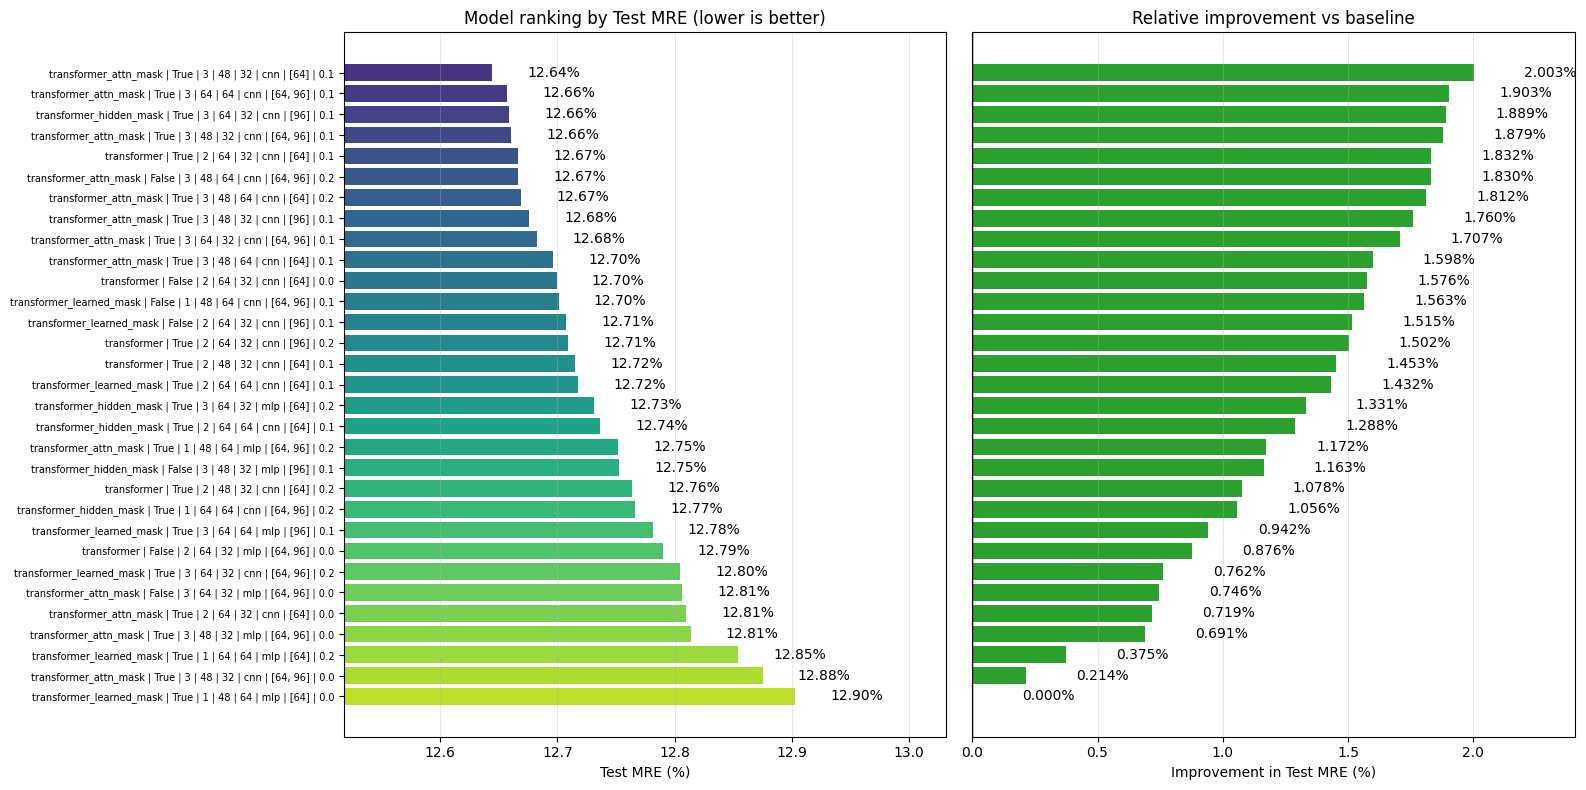
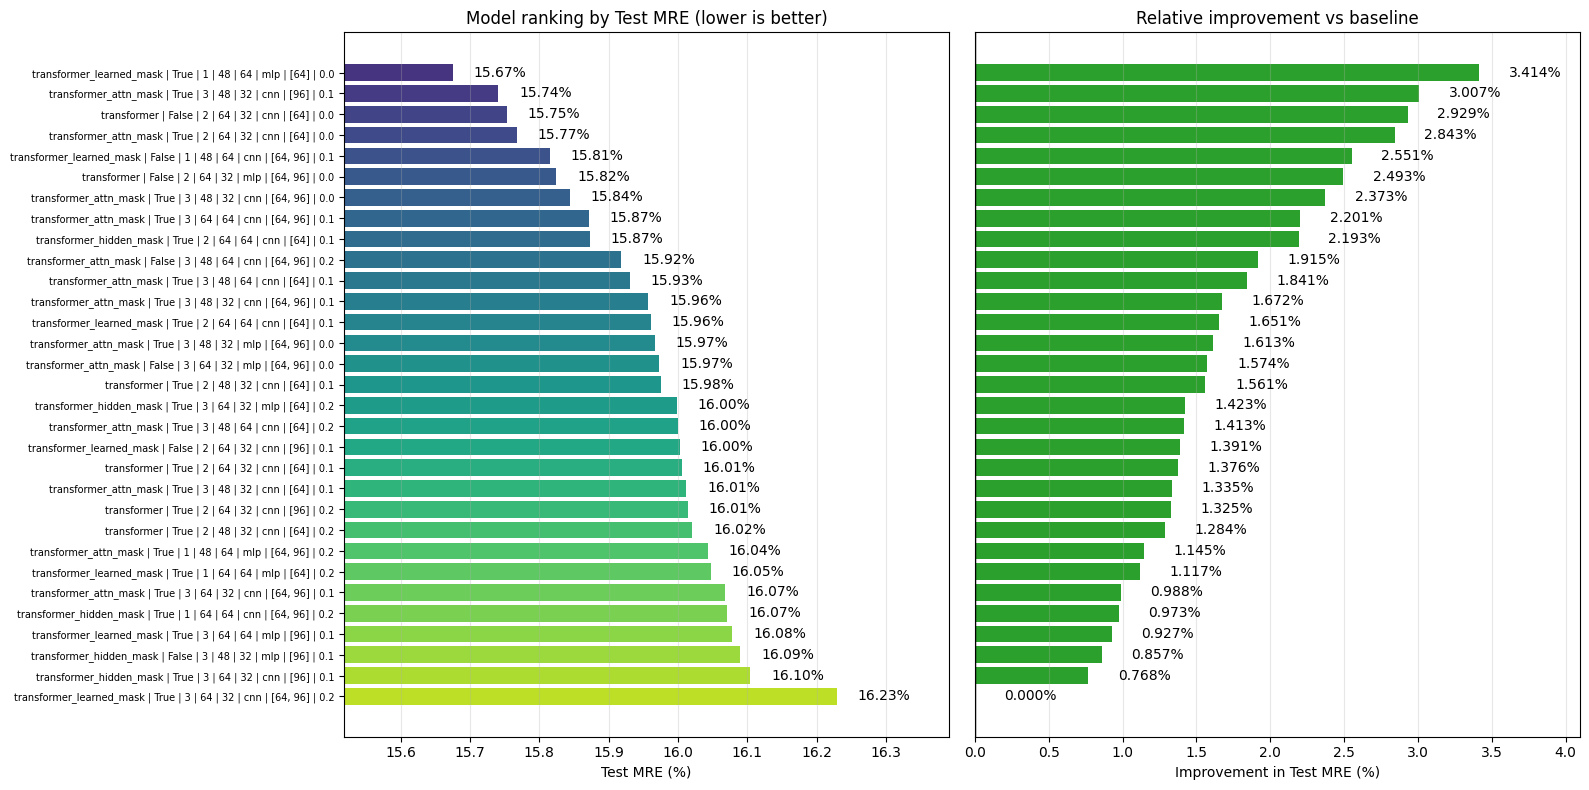

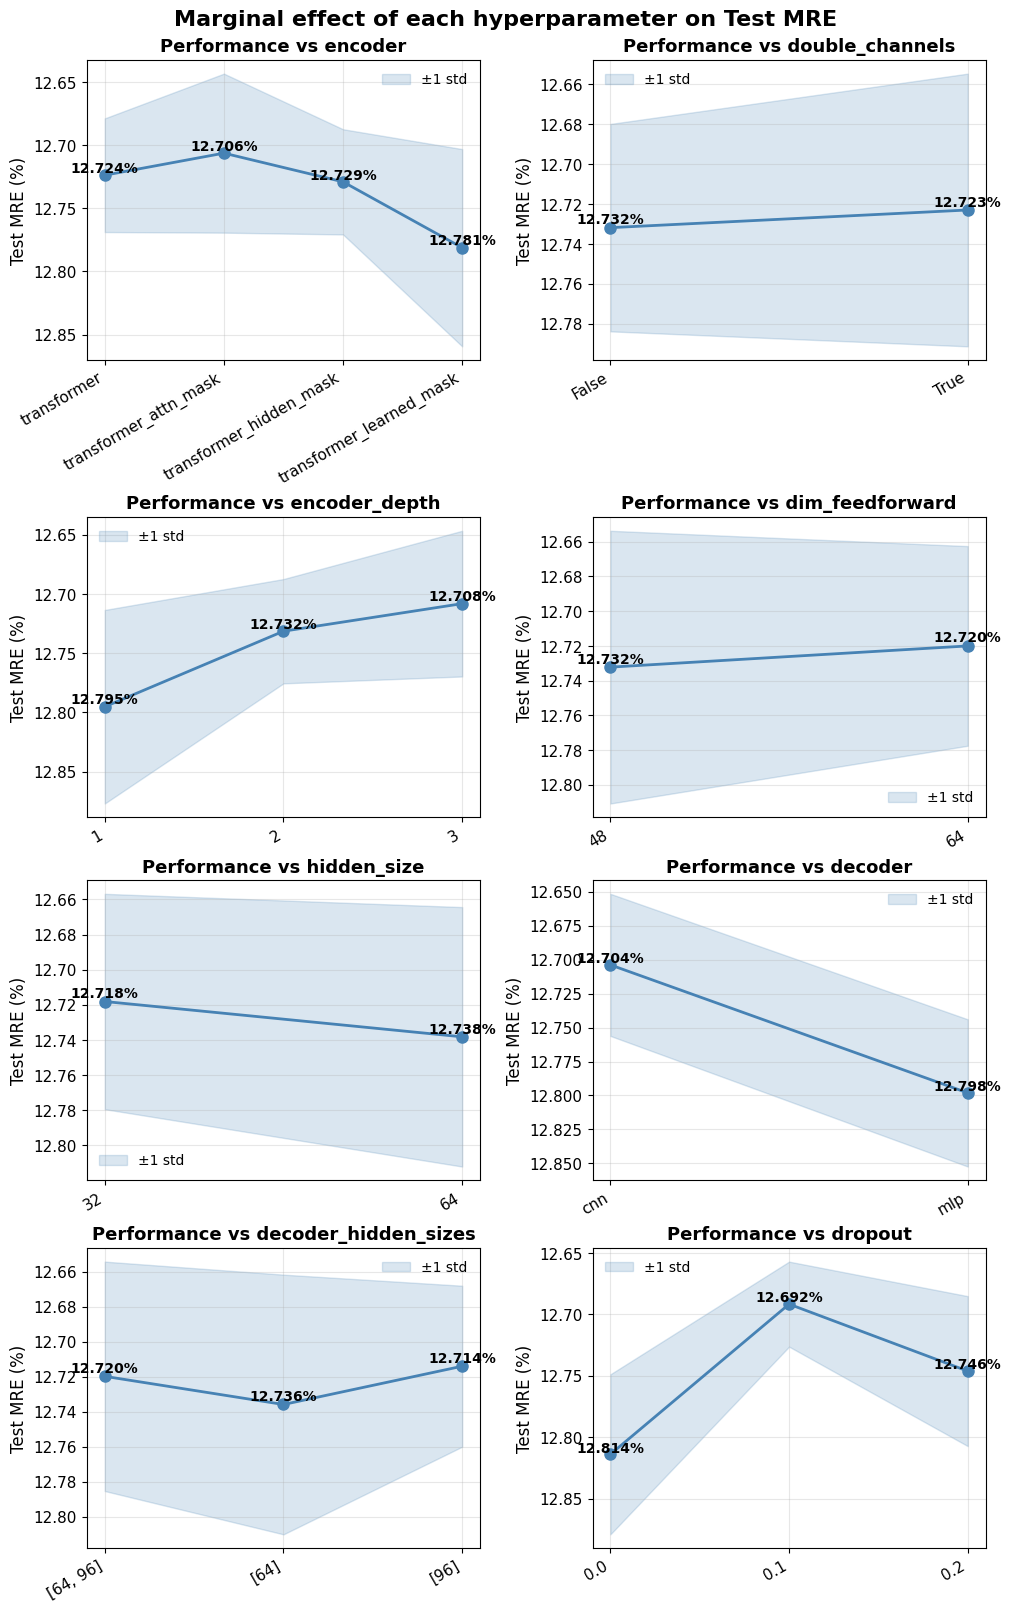
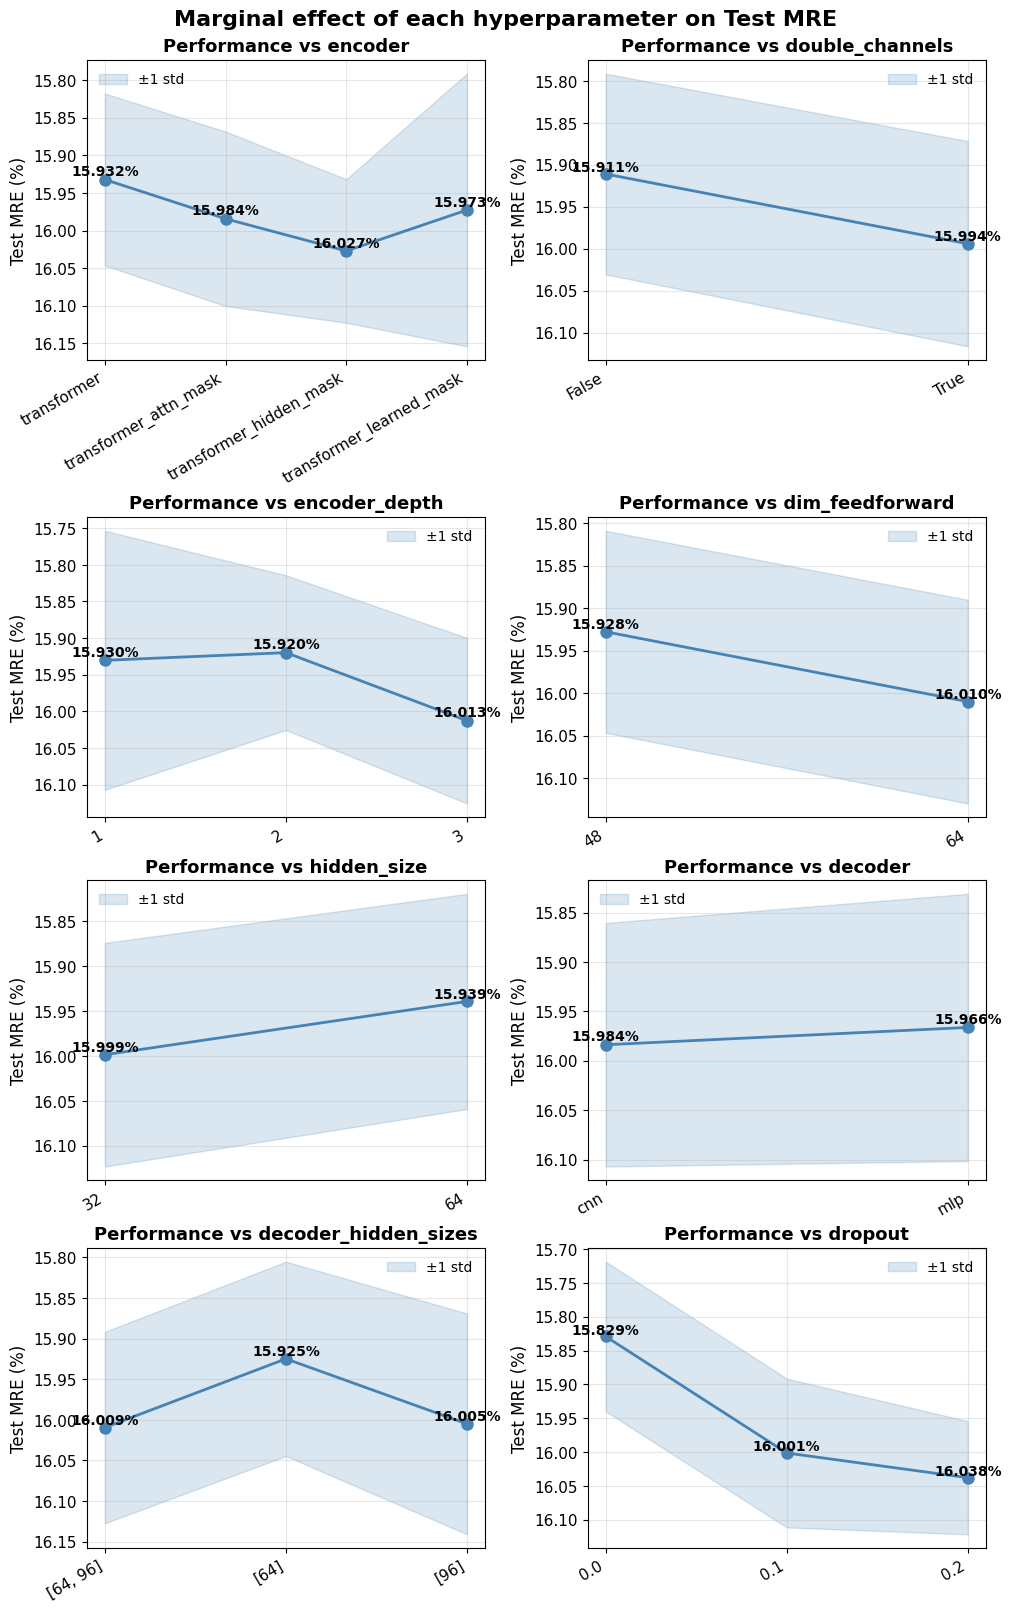

## Run 2: lags 24

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>encoder</th>
      <th>double_channels</th>
      <th>encoder_depth</th>
      <th>dim_feedforward</th>
      <th>hidden_size</th>
      <th>decoder</th>
      <th>decoder_hidden_sizes</th>
      <th>dropout</th>
      <th>val-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>65</th>
      <td>transformer</td>
      <td>True</td>
      <td>3</td>
      <td>32</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.125959</td>
    </tr>
    <tr>
      <th>11</th>
      <td>transformer</td>
      <td>True</td>
      <td>3</td>
      <td>32</td>
      <td>48</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.125983</td>
    </tr>
    <tr>
      <th>61</th>
      <td>transformer</td>
      <td>True</td>
      <td>3</td>
      <td>32</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.126086</td>
    </tr>
    <tr>
      <th>67</th>
      <td>transformer_hidden_mask</td>
      <td>True</td>
      <td>3</td>
      <td>32</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.126098</td>
    </tr>
    <tr>
      <th>22</th>
      <td>transformer</td>
      <td>False</td>
      <td>4</td>
      <td>64</td>
      <td>48</td>
      <td>cnn</td>
      <td>[64]</td>
      <td>0.2</td>
      <td>0.126107</td>
    </tr>
    <tr>
      <th>71</th>
      <td>transformer_hidden_mask</td>
      <td>True</td>
      <td>3</td>
      <td>32</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.126236</td>
    </tr>
    <tr>
      <th>73</th>
      <td>transformer_attn_mask</td>
      <td>True</td>
      <td>3</td>
      <td>32</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.126251</td>
    </tr>
    <tr>
      <th>68</th>
      <td>transformer_hidden_mask</td>
      <td>True</td>
      <td>3</td>
      <td>32</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.126297</td>
    </tr>
    <tr>
      <th>12</th>
      <td>transformer</td>
      <td>True</td>
      <td>4</td>
      <td>32</td>
      <td>48</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.126344</td>
    </tr>
    <tr>
      <th>64</th>
      <td>transformer</td>
      <td>True</td>
      <td>3</td>
      <td>32</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.126364</td>
    </tr>
    <tr>
      <th>36</th>
      <td>transformer_attn_mask</td>
      <td>False</td>
      <td>4</td>
      <td>48</td>
      <td>16</td>
      <td>cnn</td>
      <td>[64]</td>
      <td>0.0</td>
      <td>0.126366</td>
    </tr>
    <tr>
      <th>4</th>
      <td>transformer</td>
      <td>False</td>
      <td>4</td>
      <td>64</td>
      <td>48</td>
      <td>cnn</td>
      <td>[64]</td>
      <td>0.2</td>
      <td>0.126378</td>
    </tr>
    <tr>
      <th>76</th>
      <td>transformer_attn_mask</td>
      <td>True</td>
      <td>3</td>
      <td>32</td>
      <td>32</td>
      <td>cnn</td>
      <td>[96]</td>
      <td>0.1</td>
      <td>0.126387</td>
    </tr>
    <tr>
      <th>32</th>
      <td>transformer</td>
      <td>False</td>
      <td>4</td>
      <td>64</td>
      <td>48</td>
      <td>cnn</td>
      <td>[64]</td>
      <td>0.2</td>
      <td>0.126391</td>
    </tr>
    <tr>
      <th>10</th>
      <td>transformer</td>
      <td>True</td>
      <td>3</td>
      <td>32</td>
      <td>48</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.126391</td>
    </tr>
  </tbody>
</table>
</div>

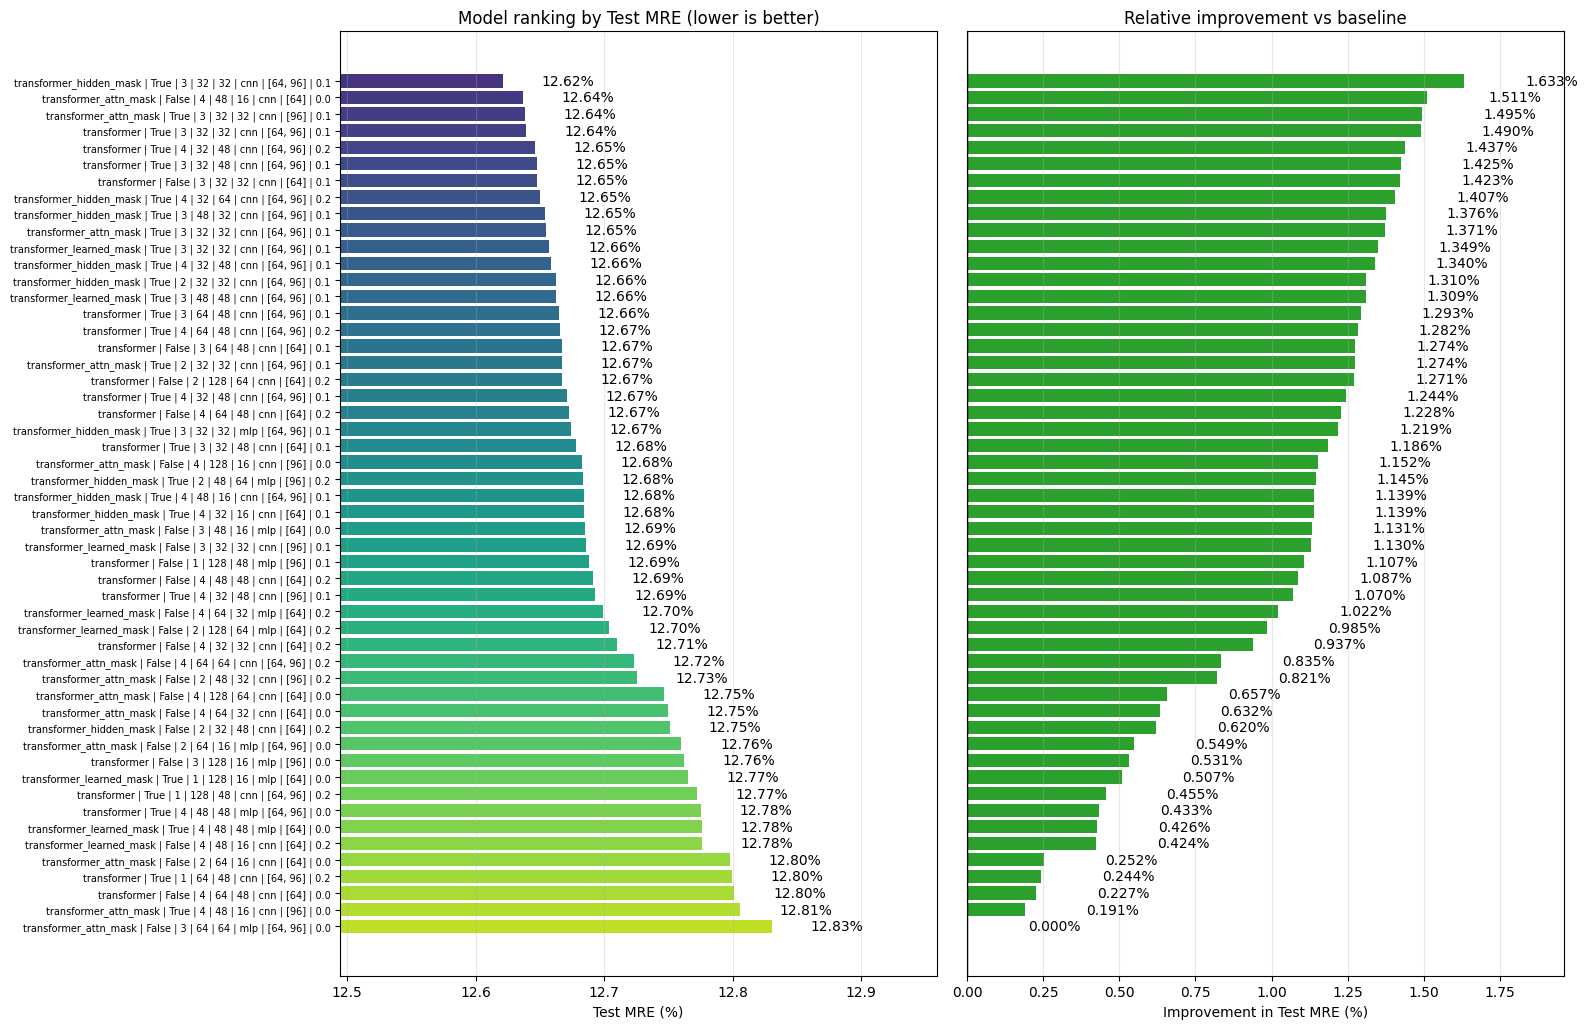
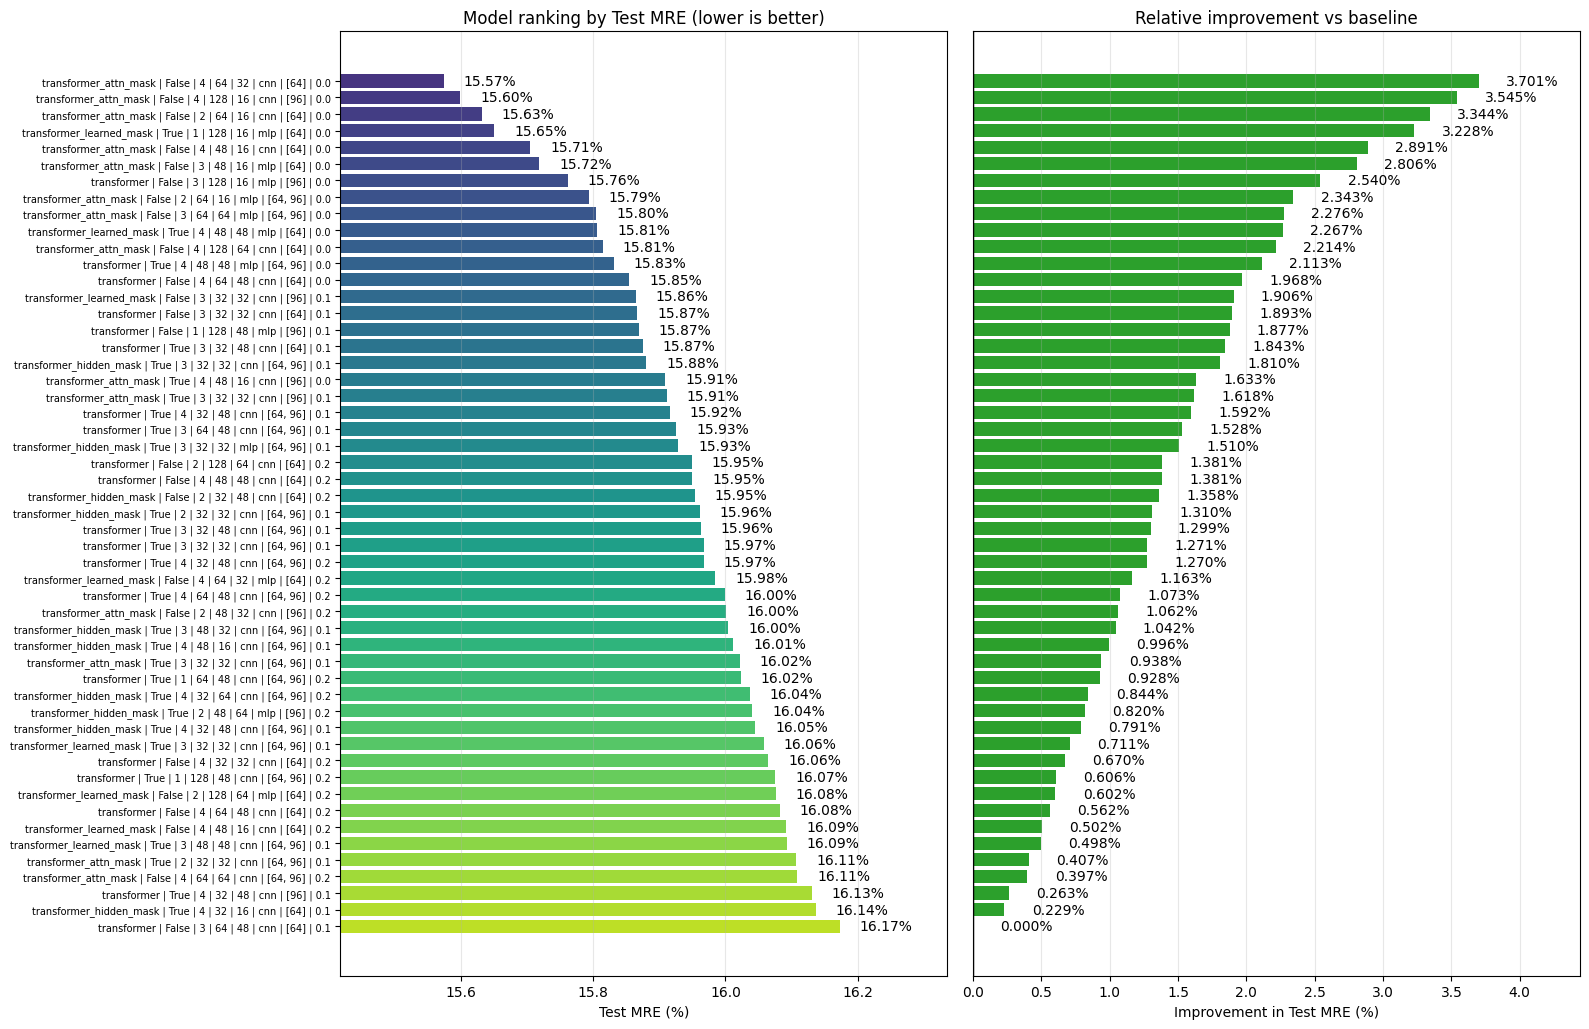

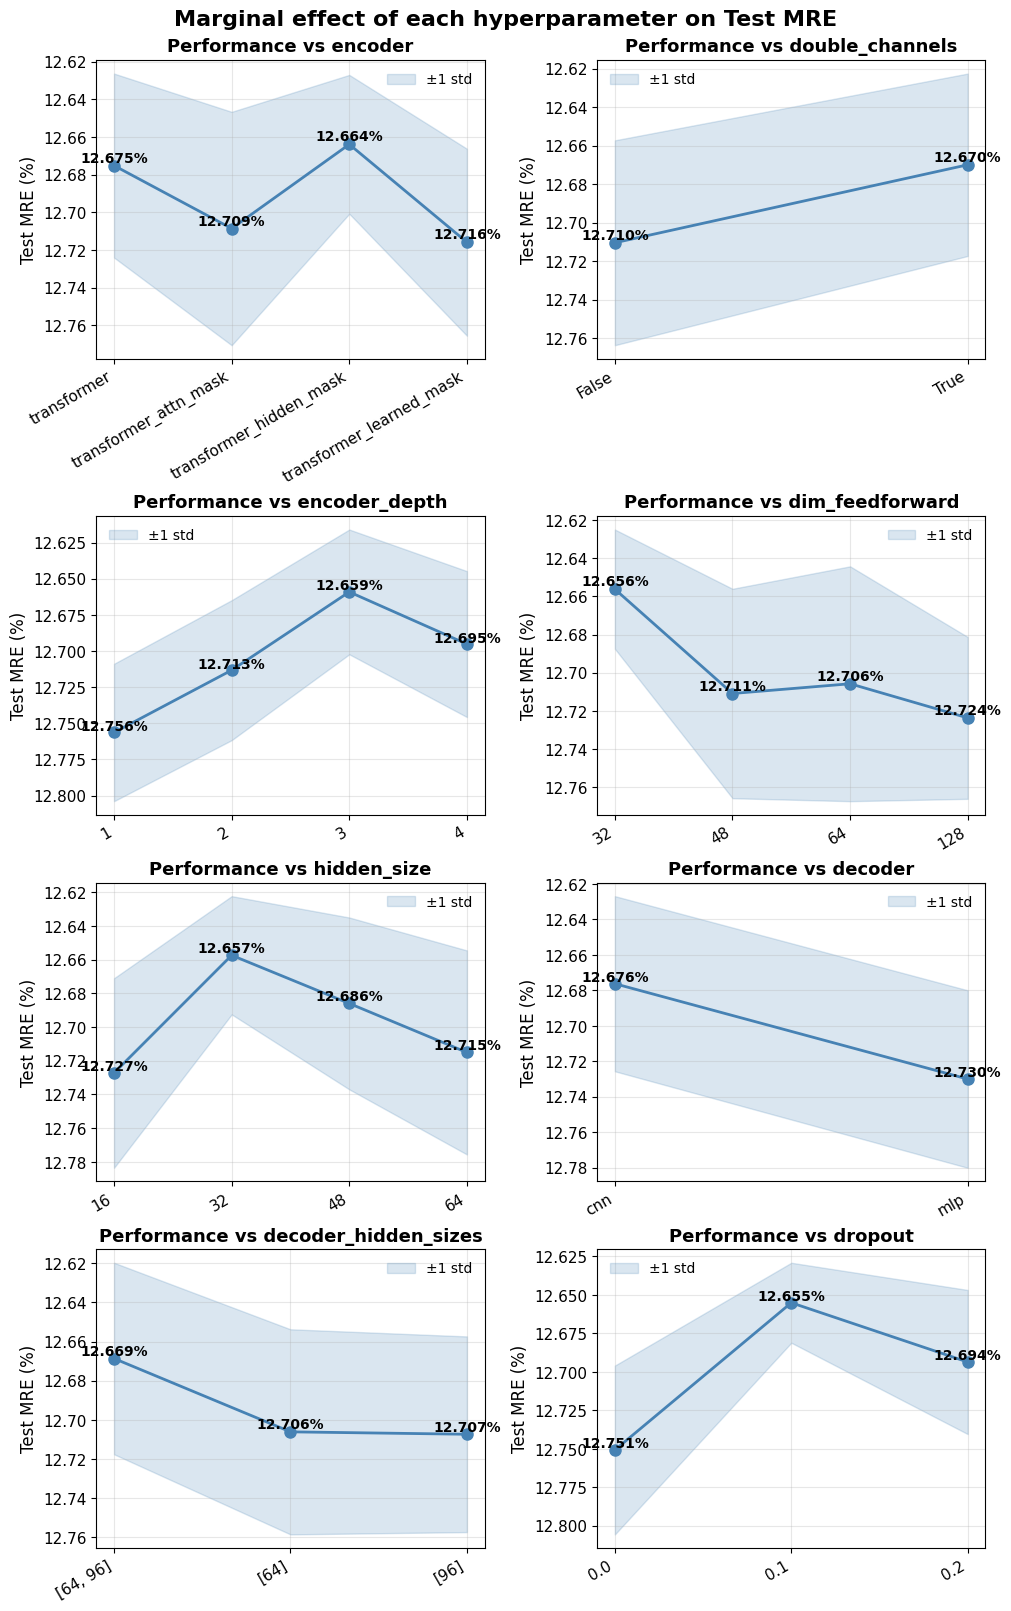
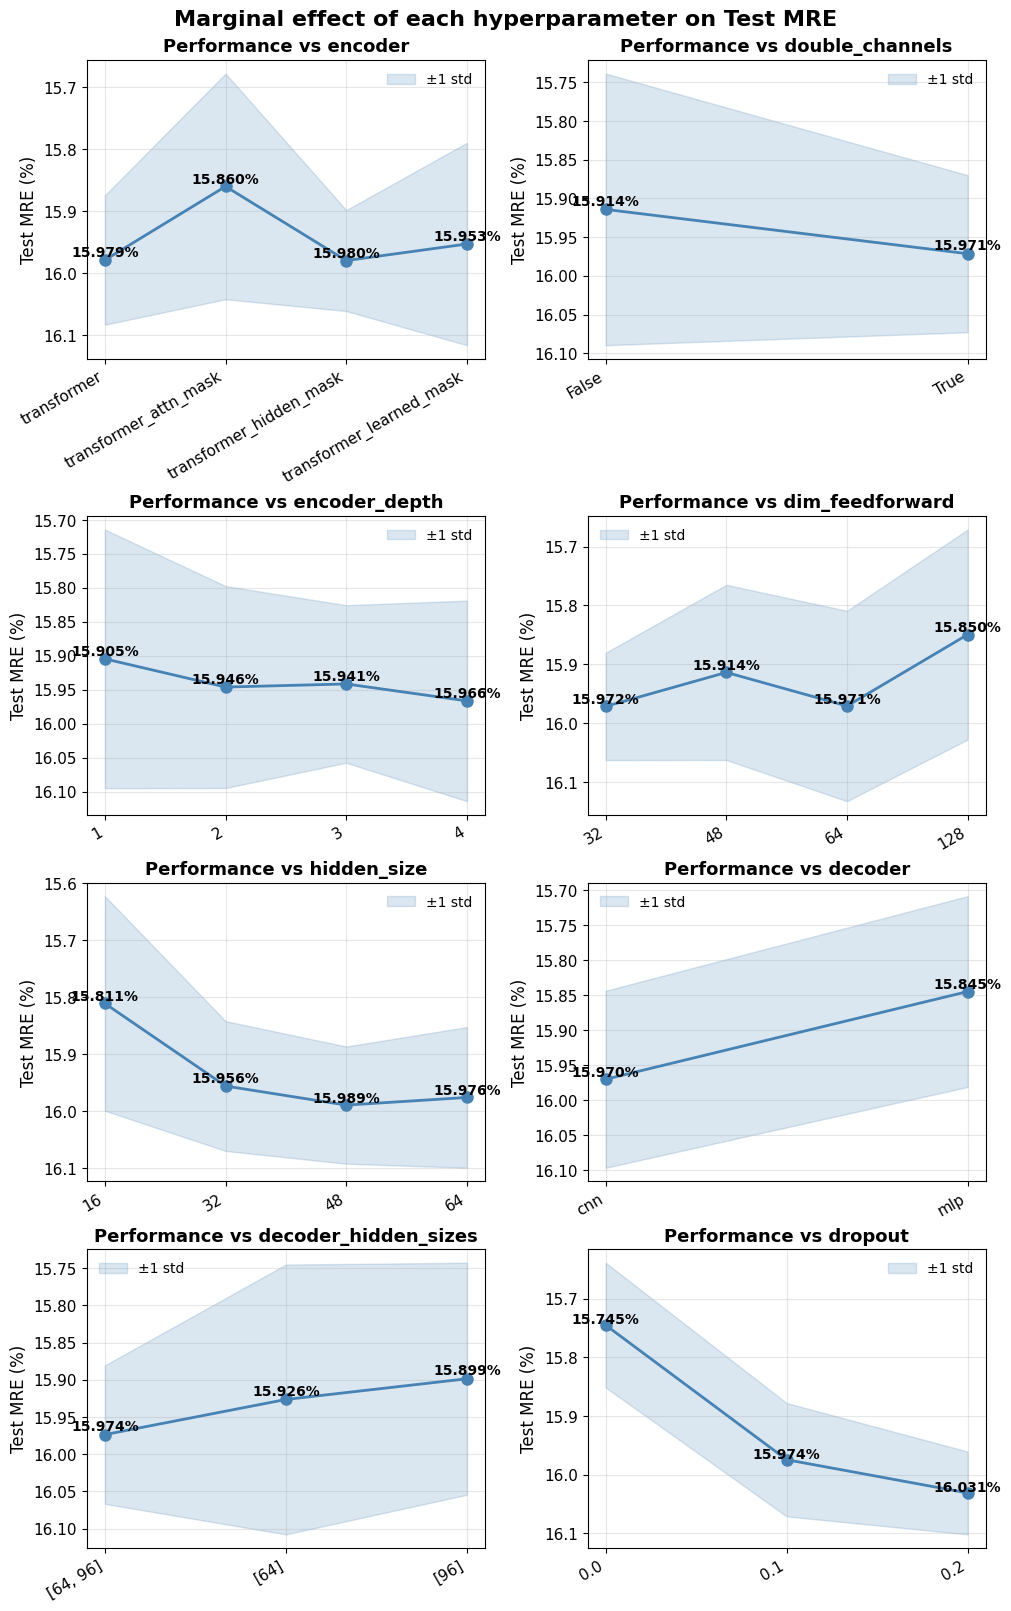

## Run 3: lags 48

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>encoder</th>
      <th>double_channels</th>
      <th>encoder_depth</th>
      <th>dim_feedforward</th>
      <th>hidden_size</th>
      <th>decoder</th>
      <th>decoder_hidden_sizes</th>
      <th>dropout</th>
      <th>val-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>53</th>
      <td>transformer_learned_mask</td>
      <td>False</td>
      <td>4</td>
      <td>48</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.125566</td>
    </tr>
    <tr>
      <th>1</th>
      <td>transformer</td>
      <td>False</td>
      <td>4</td>
      <td>48</td>
      <td>48</td>
      <td>mlp</td>
      <td>[96]</td>
      <td>0.1</td>
      <td>0.125747</td>
    </tr>
    <tr>
      <th>51</th>
      <td>transformer_learned_mask</td>
      <td>False</td>
      <td>4</td>
      <td>48</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.125771</td>
    </tr>
    <tr>
      <th>39</th>
      <td>transformer_attn_mask</td>
      <td>False</td>
      <td>4</td>
      <td>48</td>
      <td>32</td>
      <td>mlp</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.125868</td>
    </tr>
    <tr>
      <th>41</th>
      <td>transformer_attn_mask</td>
      <td>False</td>
      <td>4</td>
      <td>48</td>
      <td>32</td>
      <td>mlp</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.125879</td>
    </tr>
    <tr>
      <th>43</th>
      <td>transformer_attn_mask</td>
      <td>False</td>
      <td>4</td>
      <td>48</td>
      <td>32</td>
      <td>mlp</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.125887</td>
    </tr>
    <tr>
      <th>14</th>
      <td>transformer_attn_mask</td>
      <td>False</td>
      <td>4</td>
      <td>48</td>
      <td>48</td>
      <td>mlp</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.125896</td>
    </tr>
    <tr>
      <th>55</th>
      <td>transformer_learned_mask</td>
      <td>False</td>
      <td>4</td>
      <td>64</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.125939</td>
    </tr>
    <tr>
      <th>46</th>
      <td>transformer_learned_mask</td>
      <td>False</td>
      <td>4</td>
      <td>48</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.125954</td>
    </tr>
    <tr>
      <th>48</th>
      <td>transformer_learned_mask</td>
      <td>False</td>
      <td>4</td>
      <td>48</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.125967</td>
    </tr>
    <tr>
      <th>31</th>
      <td>transformer_attn_mask</td>
      <td>False</td>
      <td>4</td>
      <td>48</td>
      <td>48</td>
      <td>mlp</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.126021</td>
    </tr>
    <tr>
      <th>15</th>
      <td>transformer</td>
      <td>True</td>
      <td>3</td>
      <td>48</td>
      <td>32</td>
      <td>mlp</td>
      <td>[96]</td>
      <td>0.0</td>
      <td>0.126058</td>
    </tr>
    <tr>
      <th>49</th>
      <td>transformer_learned_mask</td>
      <td>False</td>
      <td>4</td>
      <td>128</td>
      <td>32</td>
      <td>cnn</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.126107</td>
    </tr>
    <tr>
      <th>32</th>
      <td>transformer_attn_mask</td>
      <td>False</td>
      <td>4</td>
      <td>48</td>
      <td>48</td>
      <td>mlp</td>
      <td>[64, 96]</td>
      <td>0.1</td>
      <td>0.126131</td>
    </tr>
    <tr>
      <th>20</th>
      <td>transformer_hidden_mask</td>
      <td>False</td>
      <td>4</td>
      <td>64</td>
      <td>48</td>
      <td>mlp</td>
      <td>[96]</td>
      <td>0.1</td>
      <td>0.126135</td>
    </tr>
  </tbody>
</table>
</div>

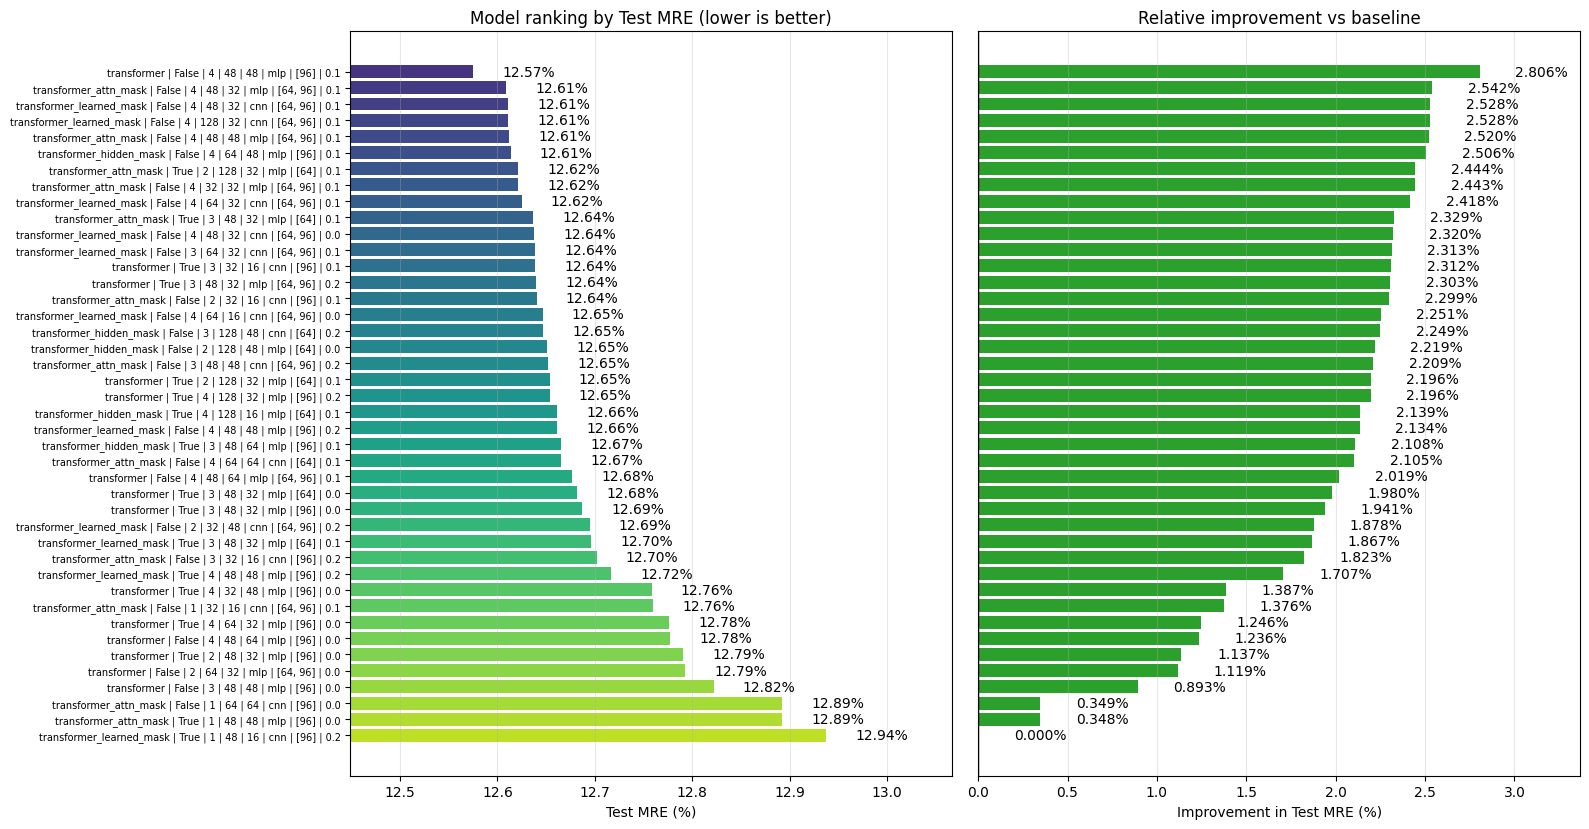
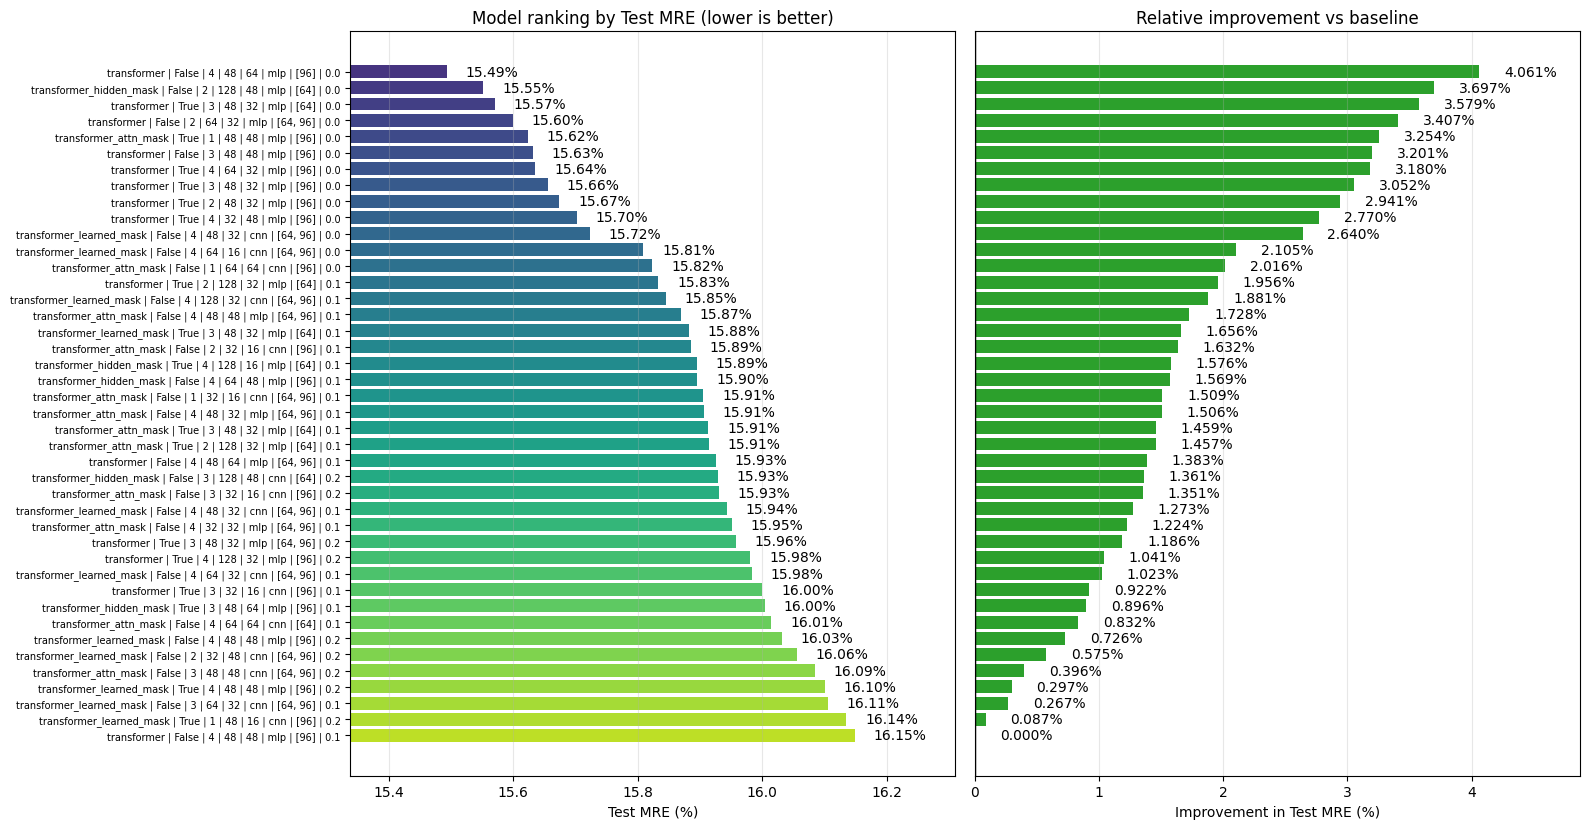

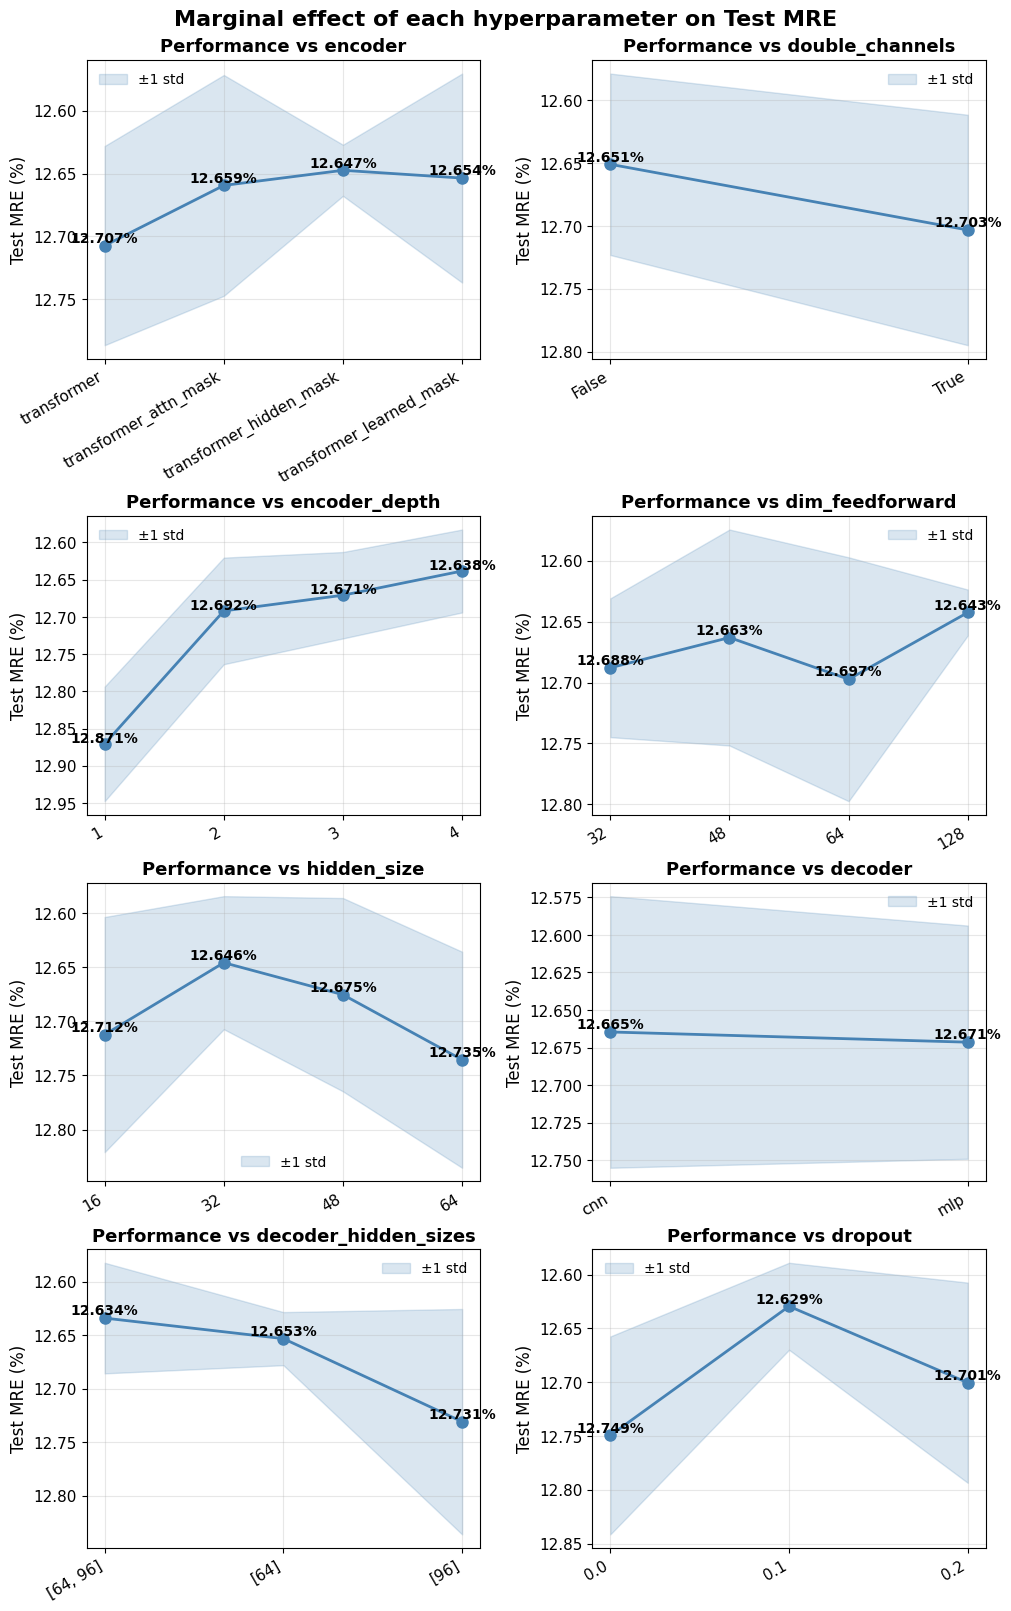
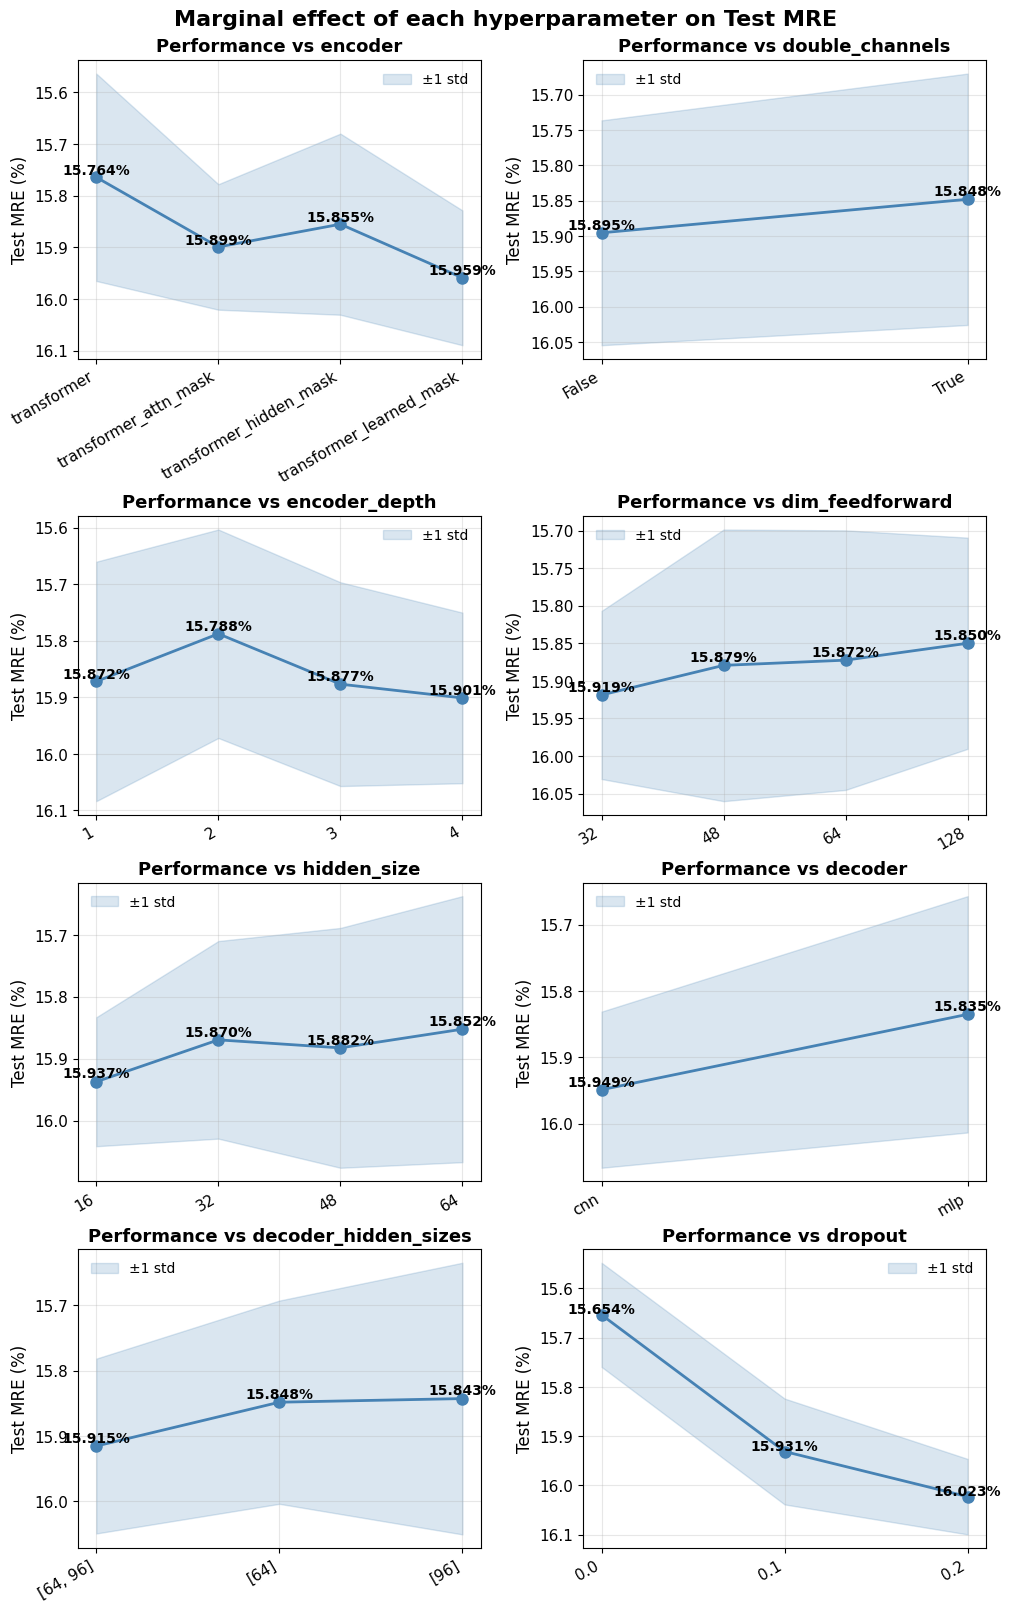

## Compare with baselines

In [37]:
dataframe_errors = pd.read_csv("outputs/5-RUN_results_TUNING/tuning all/dataframe_errors_optuna.csv")
dataframe_errors_baseline = pd.read_csv("outputs/5-RUN_results_TUNING/tuning all/baselines_24.csv")
dataframe_errors = dataframe_errors.sort_values(by="val-mre")
dataframe_errors_baseline = dataframe_errors_baseline.sort_values(by="val-mre")

# Parse the 'type' column string into a dict and expand into columns
type_df = dataframe_errors['type'].apply(lambda x: ast.literal_eval(x)).apply(pd.Series)
# Remove columns with the same value across all rows
type_df = type_df.drop(columns=['input_size', 'output_size', 'input_length', 'n_heads'])
# Add the val-mre column
type_df['val-mre'] = dataframe_errors['val-mre'].values

# Keep only 2 cols for baseline dataframe
dataframe_errors_baseline = dataframe_errors_baseline[["model", "val-mre"]]
# Make the average val-mre of the tuning runs the last row of the baseline dataframe for easier comparison in the plot
average_test_mre_baseline = dataframe_errors_baseline["val-mre"].mean()
max_test_mre = dataframe_errors_baseline["val-mre"].max()
min_test_mre = dataframe_errors_baseline["val-mre"].min()

print("Dataframe with hyperparameters ordered by test MRE:")
display(type_df.head(8))

print("Baseline models val-mre average: {:.3f}%".format(average_test_mre_baseline*100))
print("Baseline models val-mre range: [{:.3f}%, {:.3f}%]".format(min_test_mre*100, max_test_mre*100))

Dataframe with hyperparameters ordered by test MRE:


,encoder,double_channels,encoder_depth,dim_feedforward,hidden_size,decoder,decoder_hidden_sizes,dropout,val-mre
106,transformer,True,3,32,32,cnn,"[64, 96]",0.1,0.125959
52,transformer,True,3,32,48,cnn,"[64, 96]",0.1,0.125983
102,transformer,True,3,32,32,cnn,"[64, 96]",0.1,0.126086
108,transformer_hidden_mask,True,3,32,32,cnn,"[64, 96]",0.1,0.126098
63,transformer,False,4,64,48,cnn,[64],0.2,0.126107
112,transformer_hidden_mask,True,3,32,32,cnn,"[64, 96]",0.1,0.126236
114,transformer_attn_mask,True,3,32,32,cnn,"[64, 96]",0.1,0.126251
109,transformer_hidden_mask,True,3,32,32,cnn,"[64, 96]",0.1,0.126297


Baseline models val-mre average: 12.976%
Baseline models val-mre range: [12.949%, 13.004%]


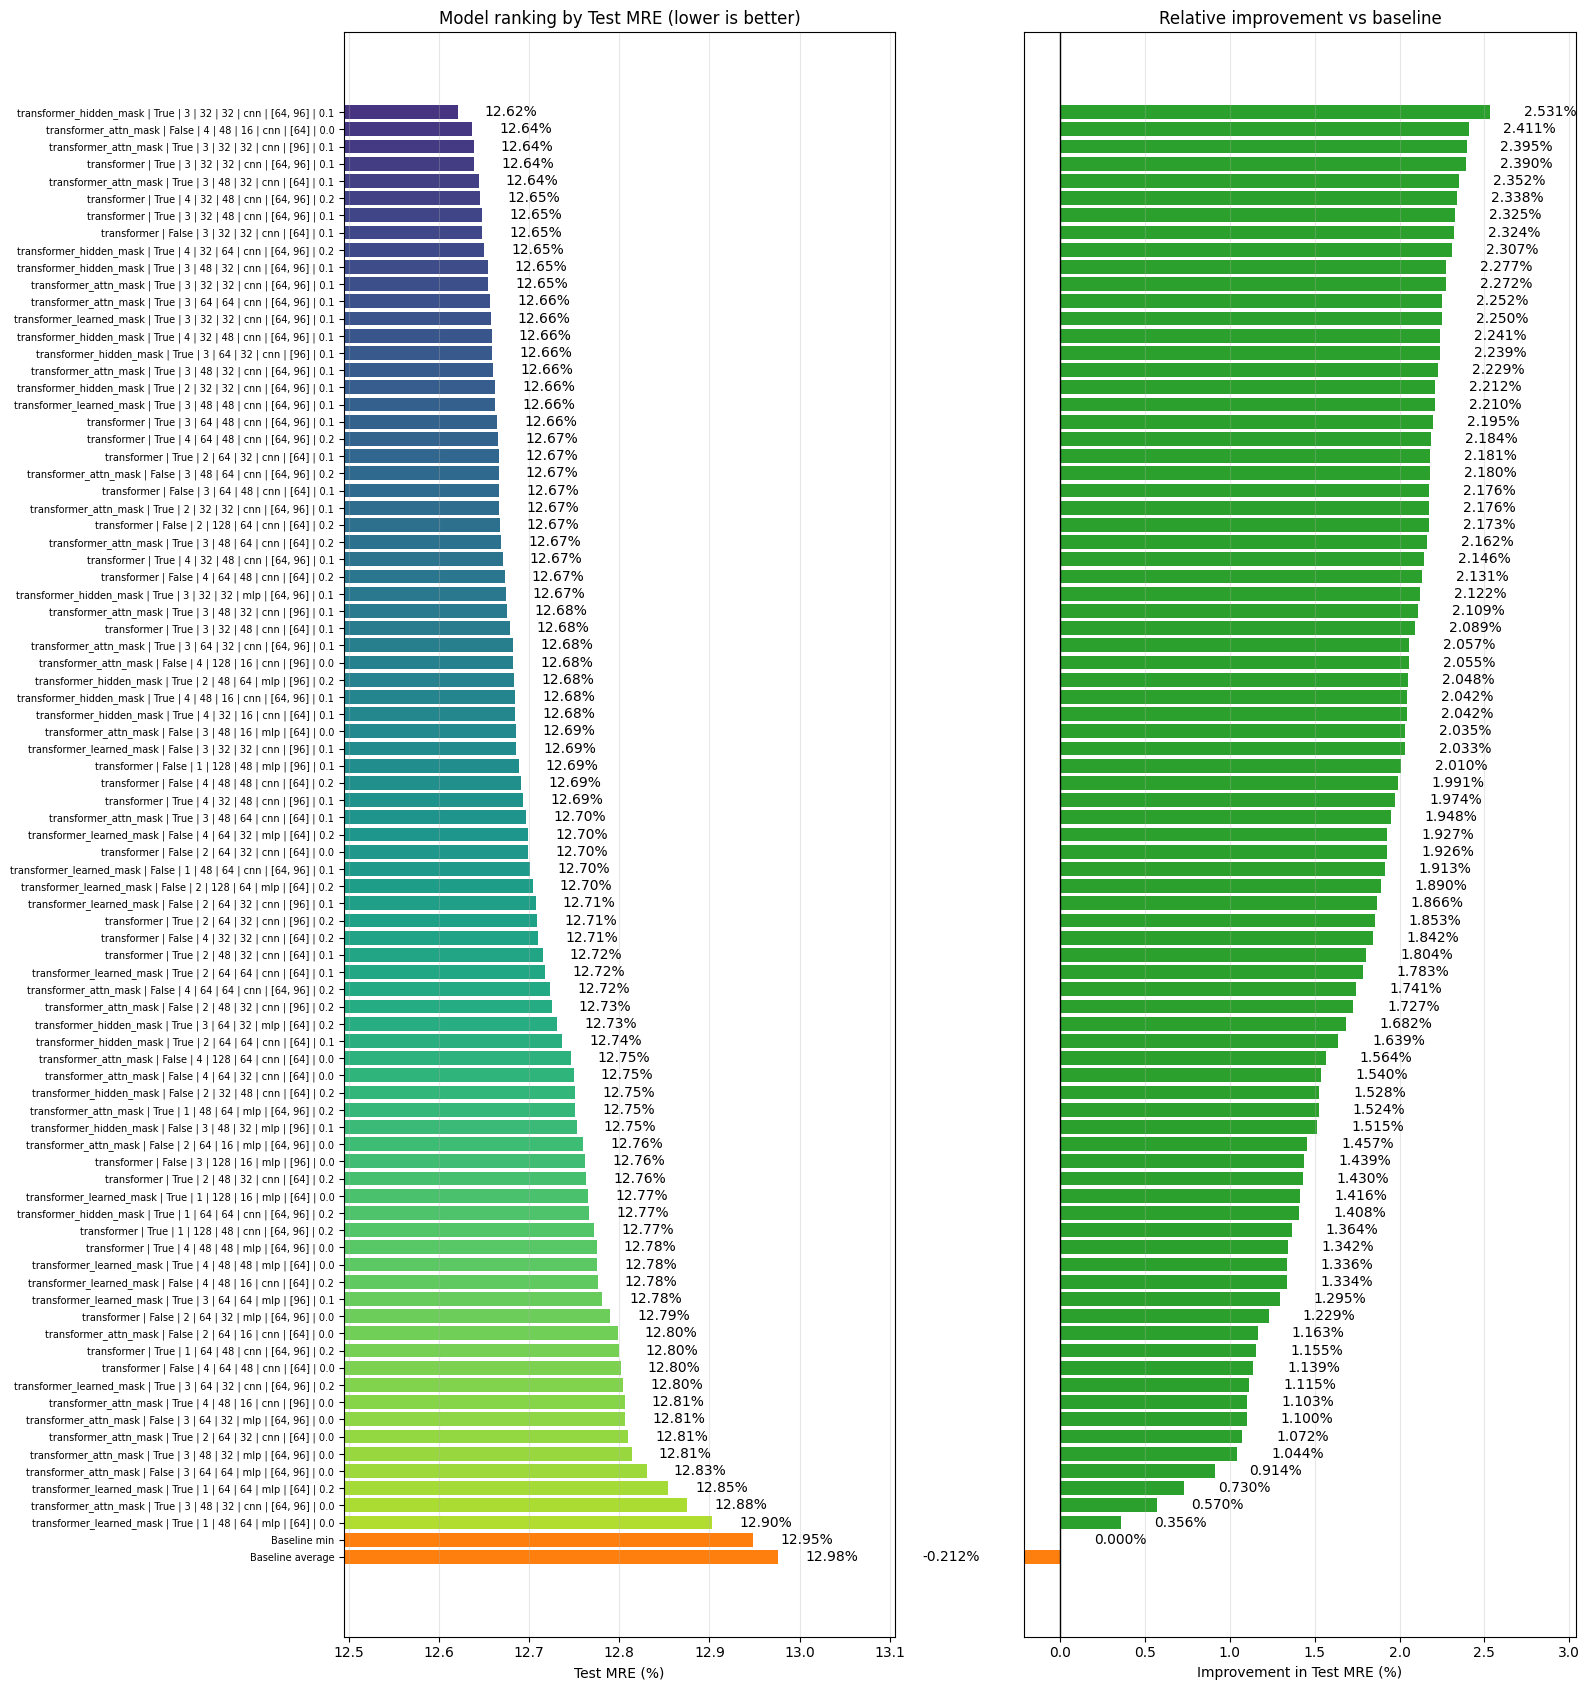

In [38]:
# Convert list columns to strings for groupby compatibility
hyperparam_cols = [c for c in type_df.columns if c != "val-mre"]
for col in hyperparam_cols:
    type_df[col] = type_df[col].apply(lambda x: str(x) if isinstance(x, list) else x)

# Aggregate duplicated configs
df_plot = (
    type_df.groupby(hyperparam_cols, as_index=False)["val-mre"].mean().sort_values("val-mre").reset_index(drop=True)
)

# Build labels
df_plot["label"] = df_plot[hyperparam_cols].astype(str).agg(" | ".join, axis=1)

# Add baseline
df_plot = pd.concat([
    df_plot,
    pd.DataFrame([{
        "label": "Baseline average",
        "val-mre": average_test_mre_baseline
    }]),
    pd.DataFrame([{
        "label": "Baseline min",
        "val-mre": min_test_mre
    }])
], ignore_index=True)

# Metrics
df_plot["val-mre_%"] = 100 * df_plot["val-mre"]

baseline = df_plot.loc[
    df_plot["label"] == "Baseline min",
    "val-mre"
].iloc[0]

df_plot["improvement_vs_T0_%"] = (
    100 * (baseline - df_plot["val-mre"]) / baseline
)

# Sort again INCLUDING baseline in the correct position
df_plot = df_plot.sort_values("val-mre").reset_index(drop=True)

# Figure
n = len(df_plot)
fig, axes = plt.subplots(1, 2, figsize=(16, max(8, n * 0.2)))

# --- Left plot: Test MRE ---
colors = list(plt.cm.viridis(np.linspace(0.15, 0.9, n)))
colors[df_plot.index[df_plot["label"] == "Baseline average"][0]] = "tab:orange"
colors[df_plot.index[df_plot["label"] == "Baseline min"][0]] = "tab:orange"

axes[0].barh(df_plot["label"], df_plot["val-mre_%"], color=colors)

axes[0].invert_yaxis()

axes[0].set(
    title="Model ranking by Test MRE (lower is better)",
    xlabel="Test MRE (%)",
    xlim=(
        df_plot["val-mre_%"].min() * 0.99,
        df_plot["val-mre_%"].max() * 1.01
    )
)

axes[0].grid(axis="x", alpha=0.3)
axes[0].tick_params(axis="y", labelsize=7)

for i, v in enumerate(df_plot["val-mre_%"]):
    axes[0].text(v + 0.03, i, f"{v:.2f}%", va="center", fontsize=10)

# --- Right plot: Improvement ---
imp_colors = [
    "tab:orange" if lbl == "Baseline average"
    else "tab:blue" if "Normal_training" in lbl
    else "tab:green" if x >= 0
    else "tab:red"
    for lbl, x in zip(df_plot["label"], df_plot["improvement_vs_T0_%"])
]

axes[1].barh(df_plot["label"], df_plot["improvement_vs_T0_%"], color=imp_colors)

axes[1].invert_yaxis()
axes[1].axvline(0, color="black", linewidth=1)

axes[1].set(
    title="Relative improvement vs baseline",
    xlabel="Improvement in Test MRE (%)",
    xlim=(
        df_plot["improvement_vs_T0_%"].min(),
        df_plot["improvement_vs_T0_%"].max() * 1.2
    )
)

axes[1].grid(axis="x", alpha=0.3)
axes[1].set_yticklabels([])
axes[1].tick_params(axis="y", left=False)

for i, v in enumerate(df_plot["improvement_vs_T0_%"]):
    axes[1].text(
        v + (0.2 if v >= 0 else -0.6),
        i,
        f"{v:.3f}%",
        va="center",
        fontsize=10
    )

plt.tight_layout()
plt.savefig("hyperparams_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

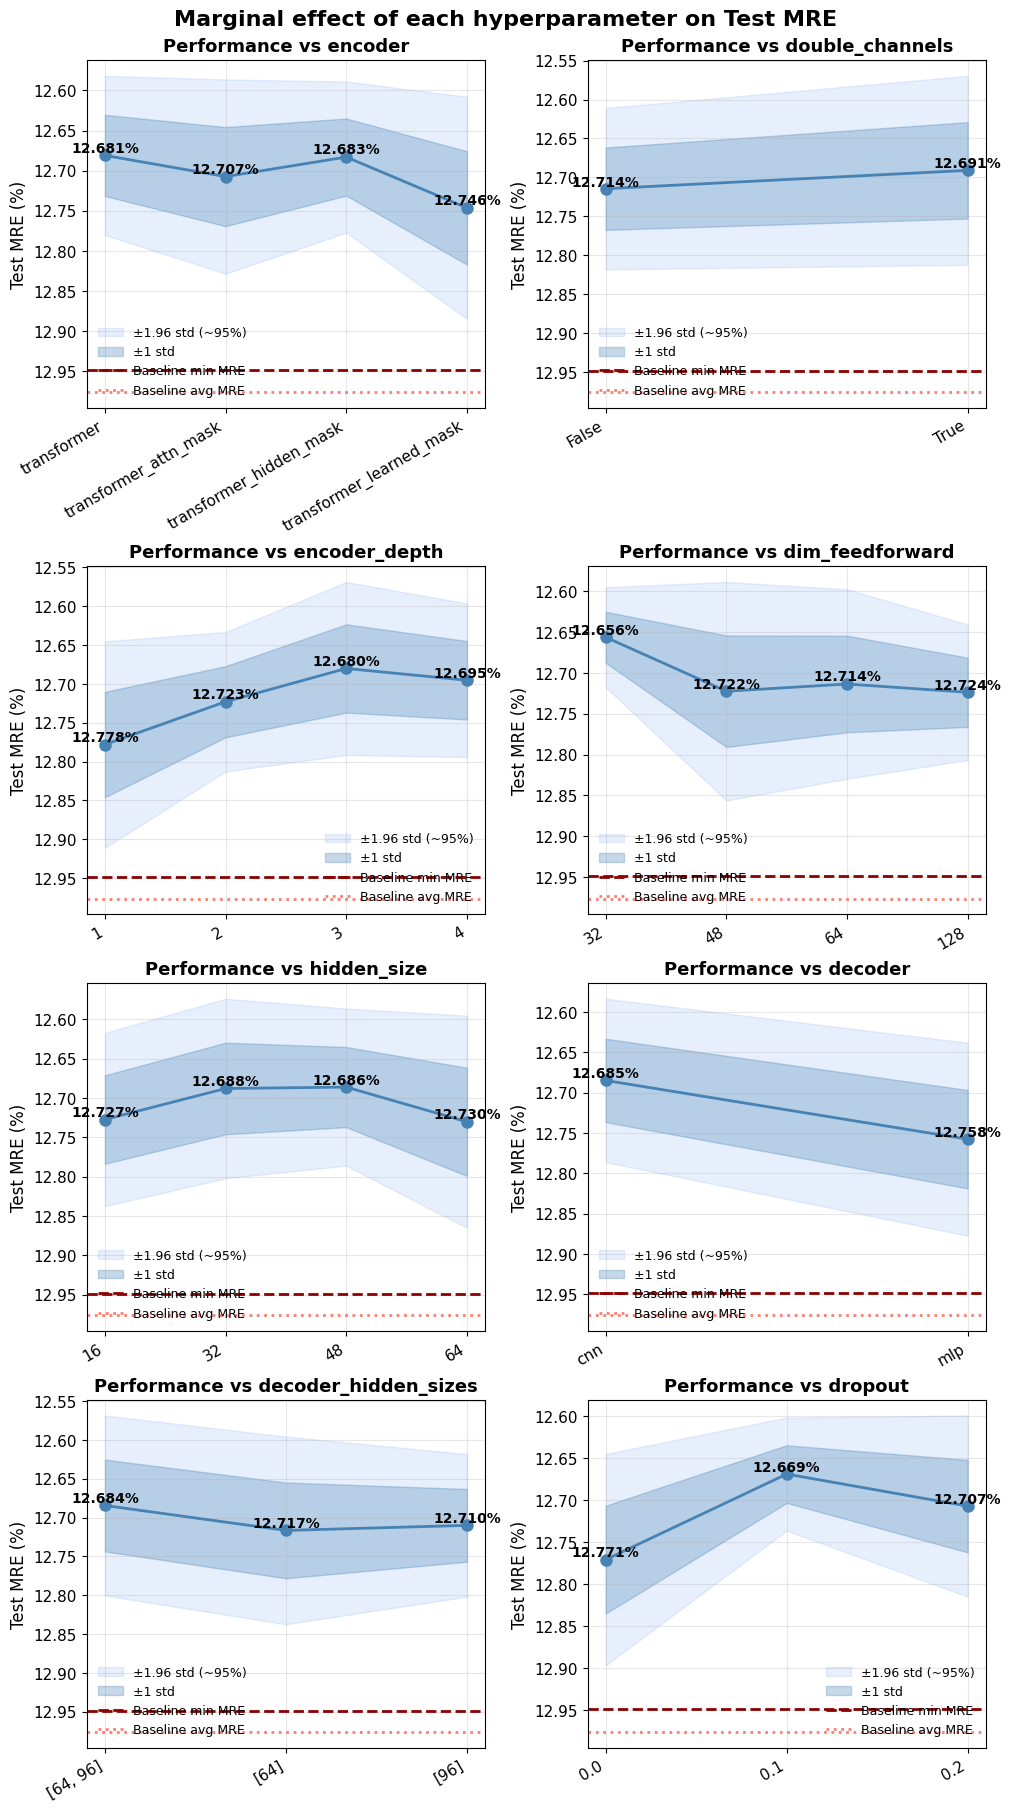

In [39]:
n_rows = 4
n_cols = int(np.ceil(len(hyperparam_cols) / n_rows))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(5 * n_cols, 4.5 * n_rows),
    constrained_layout=True
)

axes = axes.flatten()

# Baselines in %
baseline_min_pct = min_test_mre * 100
baseline_avg_pct = average_test_mre_baseline * 100

for idx, col in enumerate(hyperparam_cols):

    ax = axes[idx]

    perf = (
        type_df
        .groupby(col)["val-mre"]
        .agg(["mean", "std"])
        .reset_index()
        .sort_values(col)
    )

    x_vals = np.arange(len(perf))

    mean_pct = perf["mean"] * 100
    std_pct  = perf["std"]  * 100
    ci95_pct = 1.96 * std_pct

    # Main curve
    ax.plot(
        x_vals,
        mean_pct,
        marker="o",
        linewidth=2,
        markersize=8,
        color="steelblue"
    )

    # ±1.96 std band (~95%)
    ax.fill_between(
        x_vals,
        mean_pct - ci95_pct,
        mean_pct + ci95_pct,
        alpha=0.15,
        color="cornflowerblue",
        label="±1.96 std (~95%)"
    )

    # ±1 std band
    ax.fill_between(
        x_vals,
        mean_pct - std_pct,
        mean_pct + std_pct,
        alpha=0.30,
        color="steelblue",
        label="±1 std"
    )

    # Baseline min MRE
    ax.axhline(
        baseline_min_pct,
        color="darkred",
        linestyle="--",
        linewidth=2,
        label="Baseline min MRE"
    )

    # Baseline average MRE
    ax.axhline(
        baseline_avg_pct,
        color="salmon",
        linestyle=":",
        linewidth=2,
        label="Baseline avg MRE"
    )

    ax.set_xticks(x_vals)

    ax.set_xticklabels(
        perf[col].astype(str),
        rotation=30,
        ha="right",
        fontsize=11
    )

    ax.set_ylabel("Test MRE (%)", fontsize=12)

    ax.set_title(
        f"Performance vs {col}",
        fontsize=13,
        fontweight="bold"
    )

    ax.tick_params(axis="y", labelsize=11)

    ax.grid(alpha=0.3)

    # Lower is better
    ax.invert_yaxis()

    ax.legend(fontsize=9, loc="best", frameon=False)

    # Annotate points
    y_offset = ci95_pct.max() * 0.03 if ci95_pct.max() > 0 else 0.02

    for x, (_, row) in zip(x_vals, perf.iterrows()):

        ax.text(
            x,
            row["mean"] * 100 - y_offset,
            f"{row['mean'] * 100:.3f}%",
            ha="center",
            fontsize=10,
            fontweight="bold"
        )

# Hide unused axes
for idx in range(len(hyperparam_cols), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle(
    "Marginal effect of each hyperparameter on Test MRE",
    fontsize=16,
    fontweight="bold"
)

plt.savefig(
    "hyperparam_marginal_effects_baseline.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## Compare 24

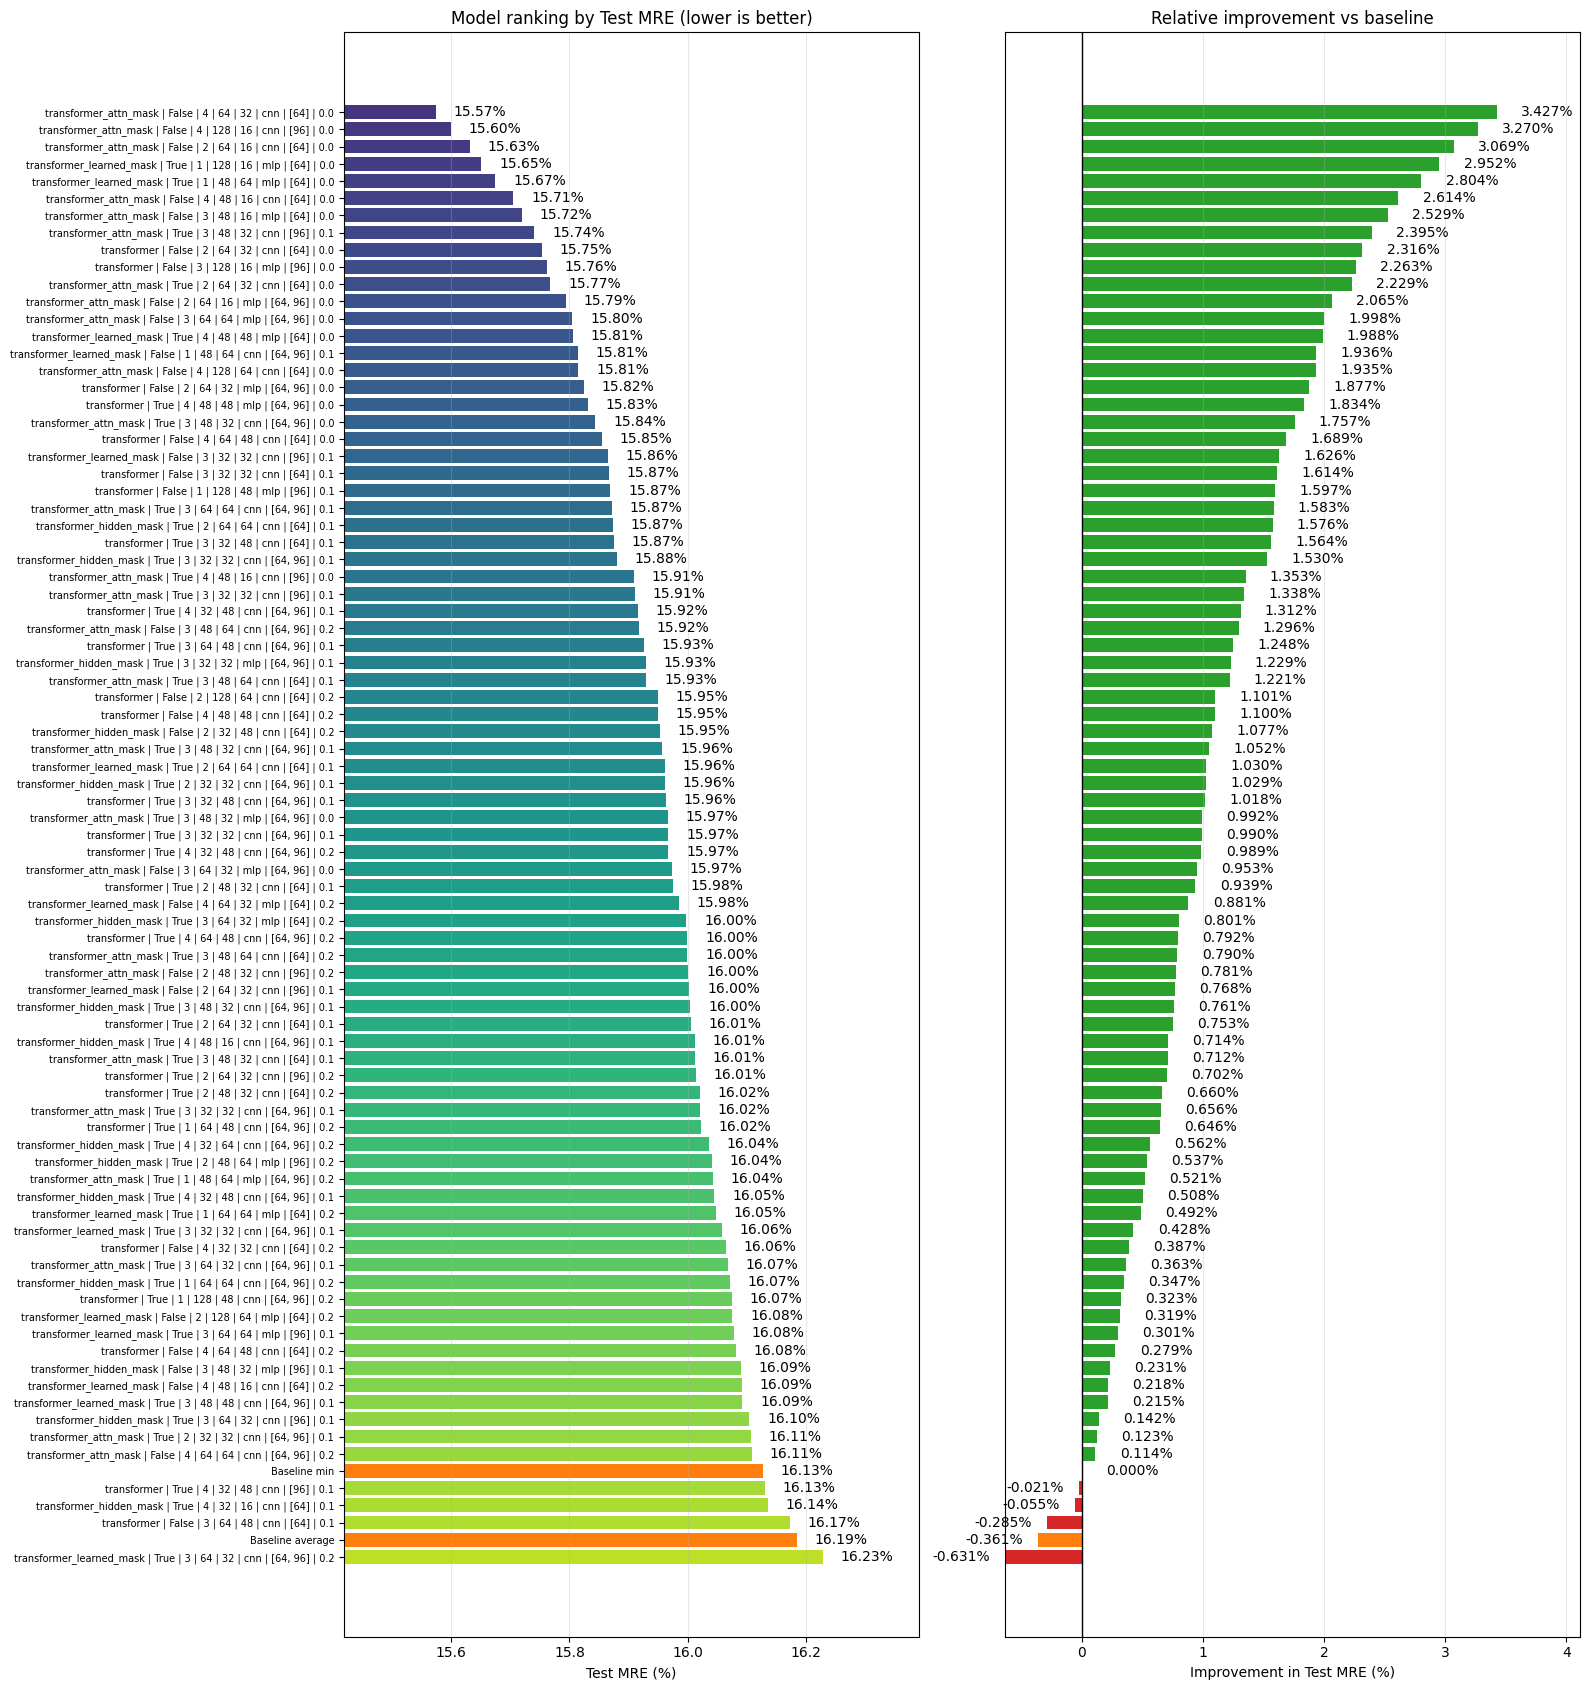

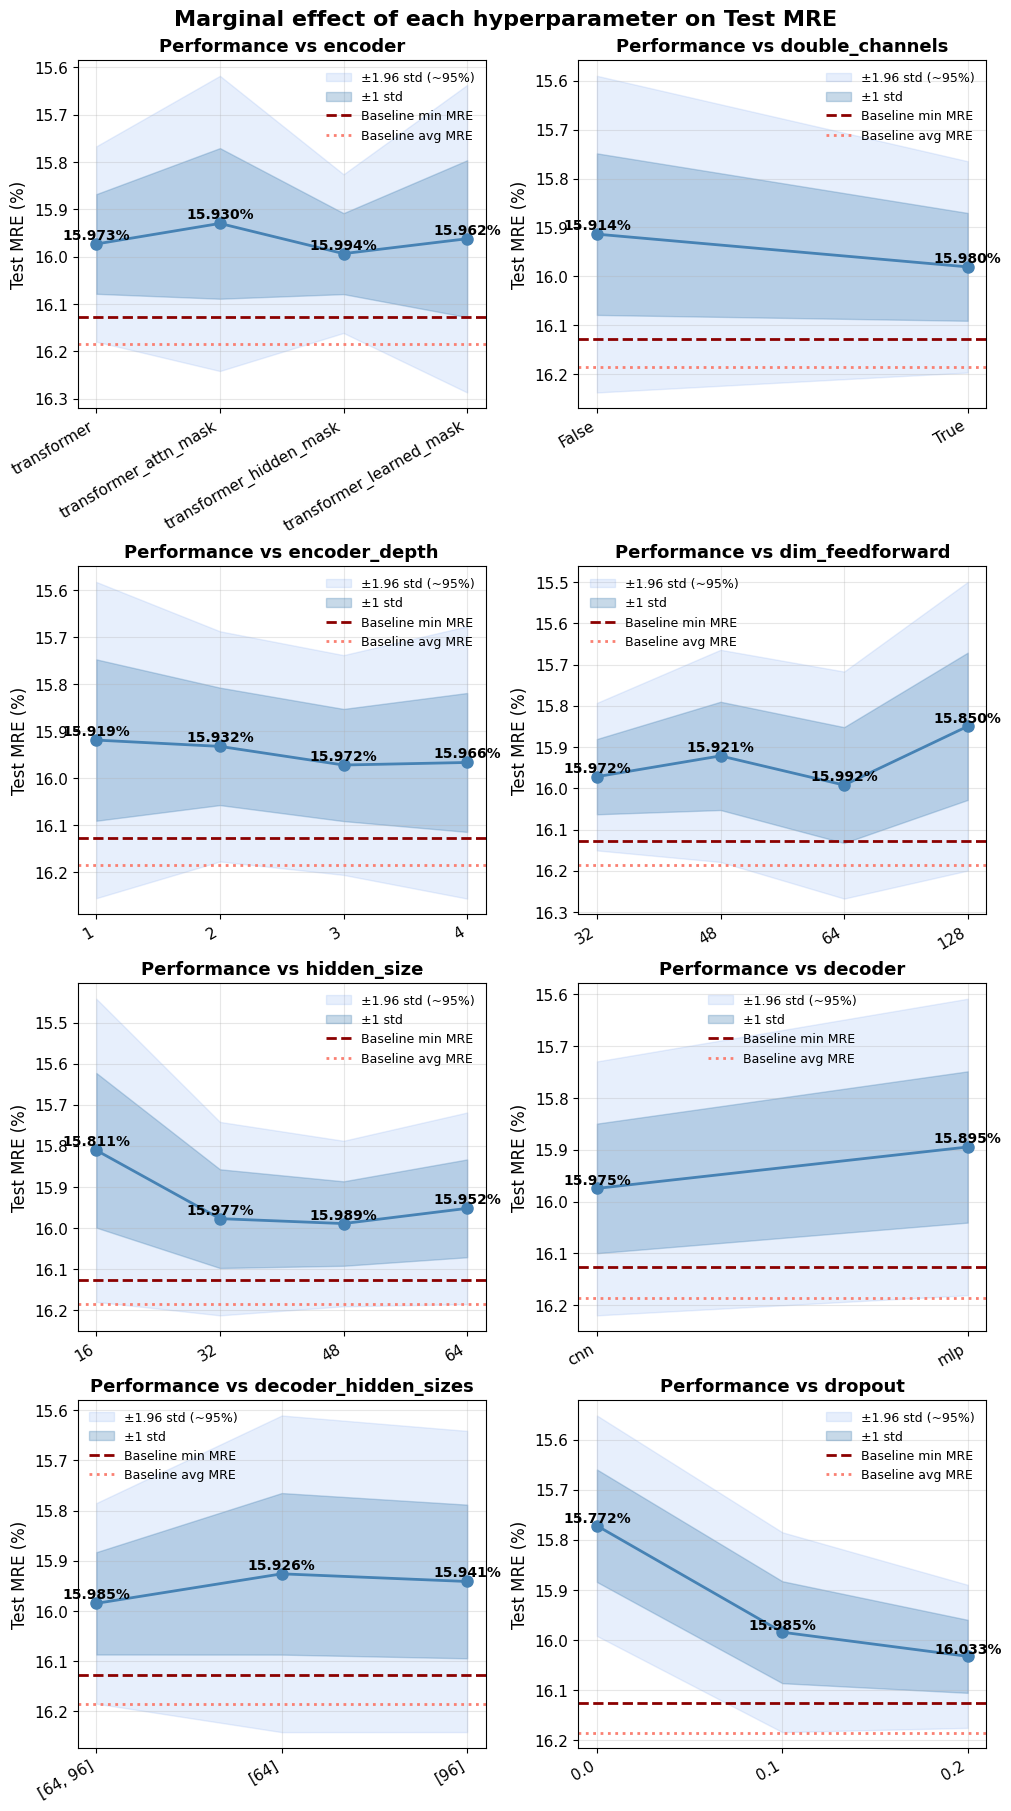

## Compare 48

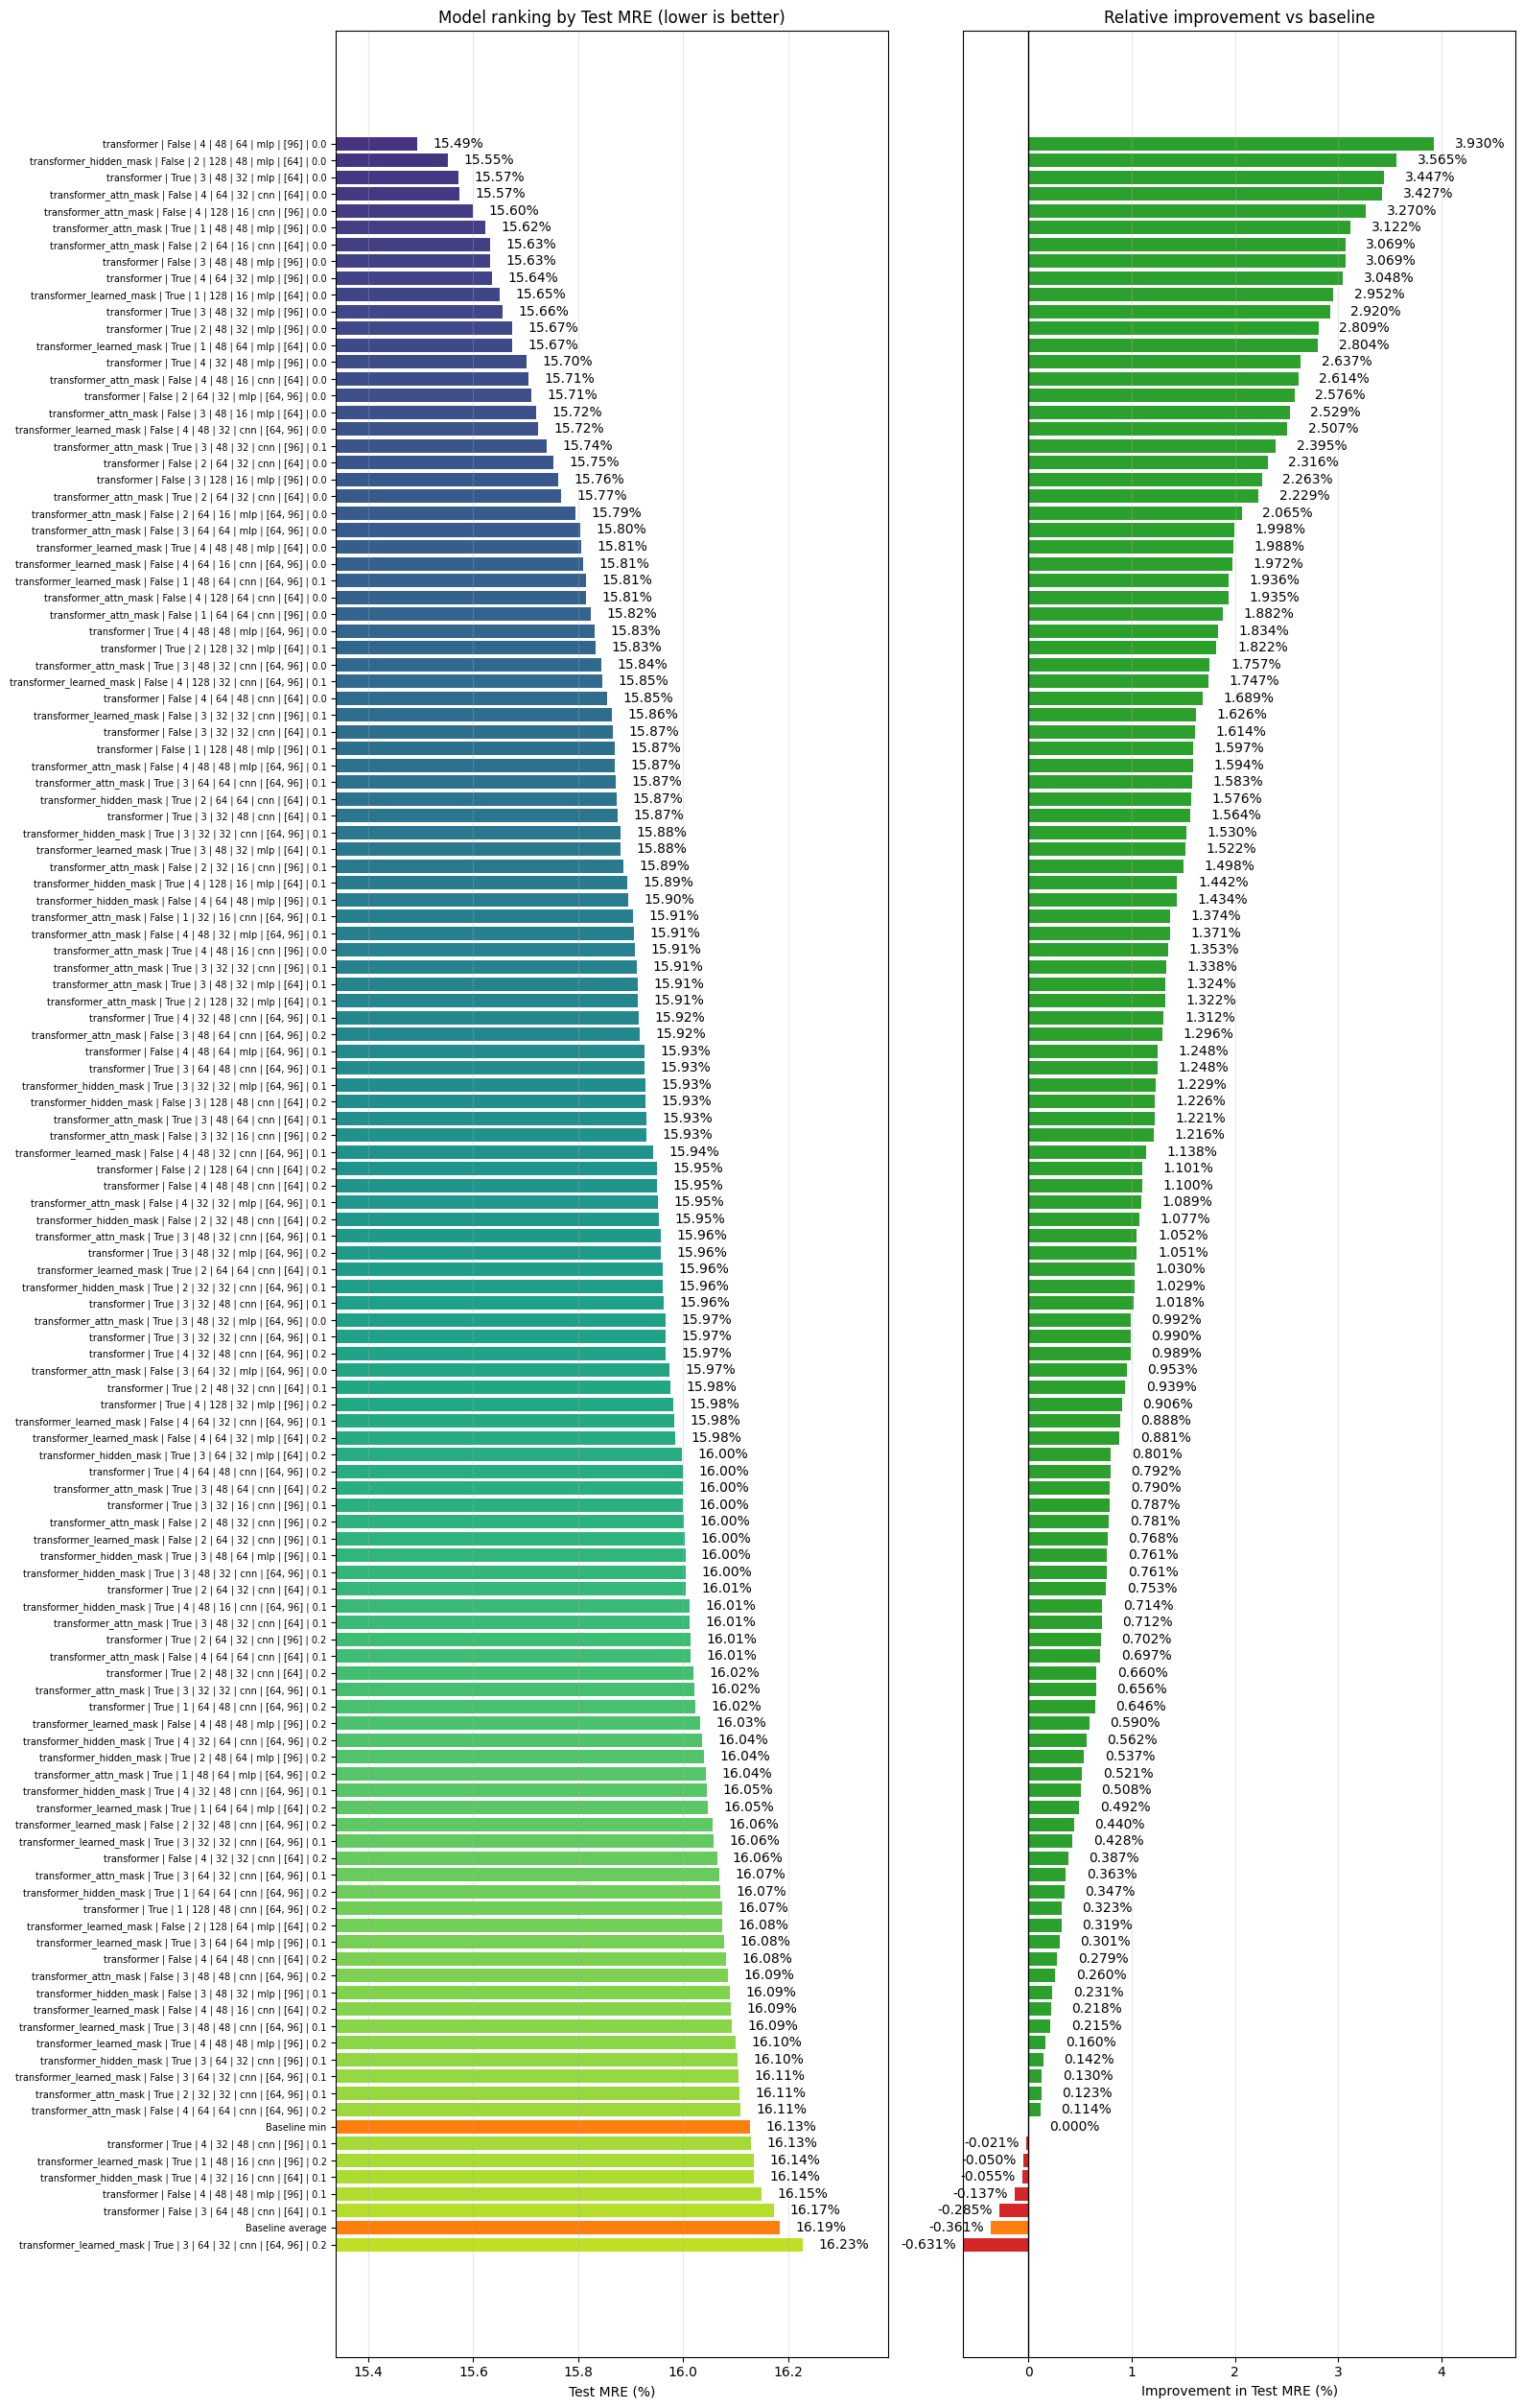

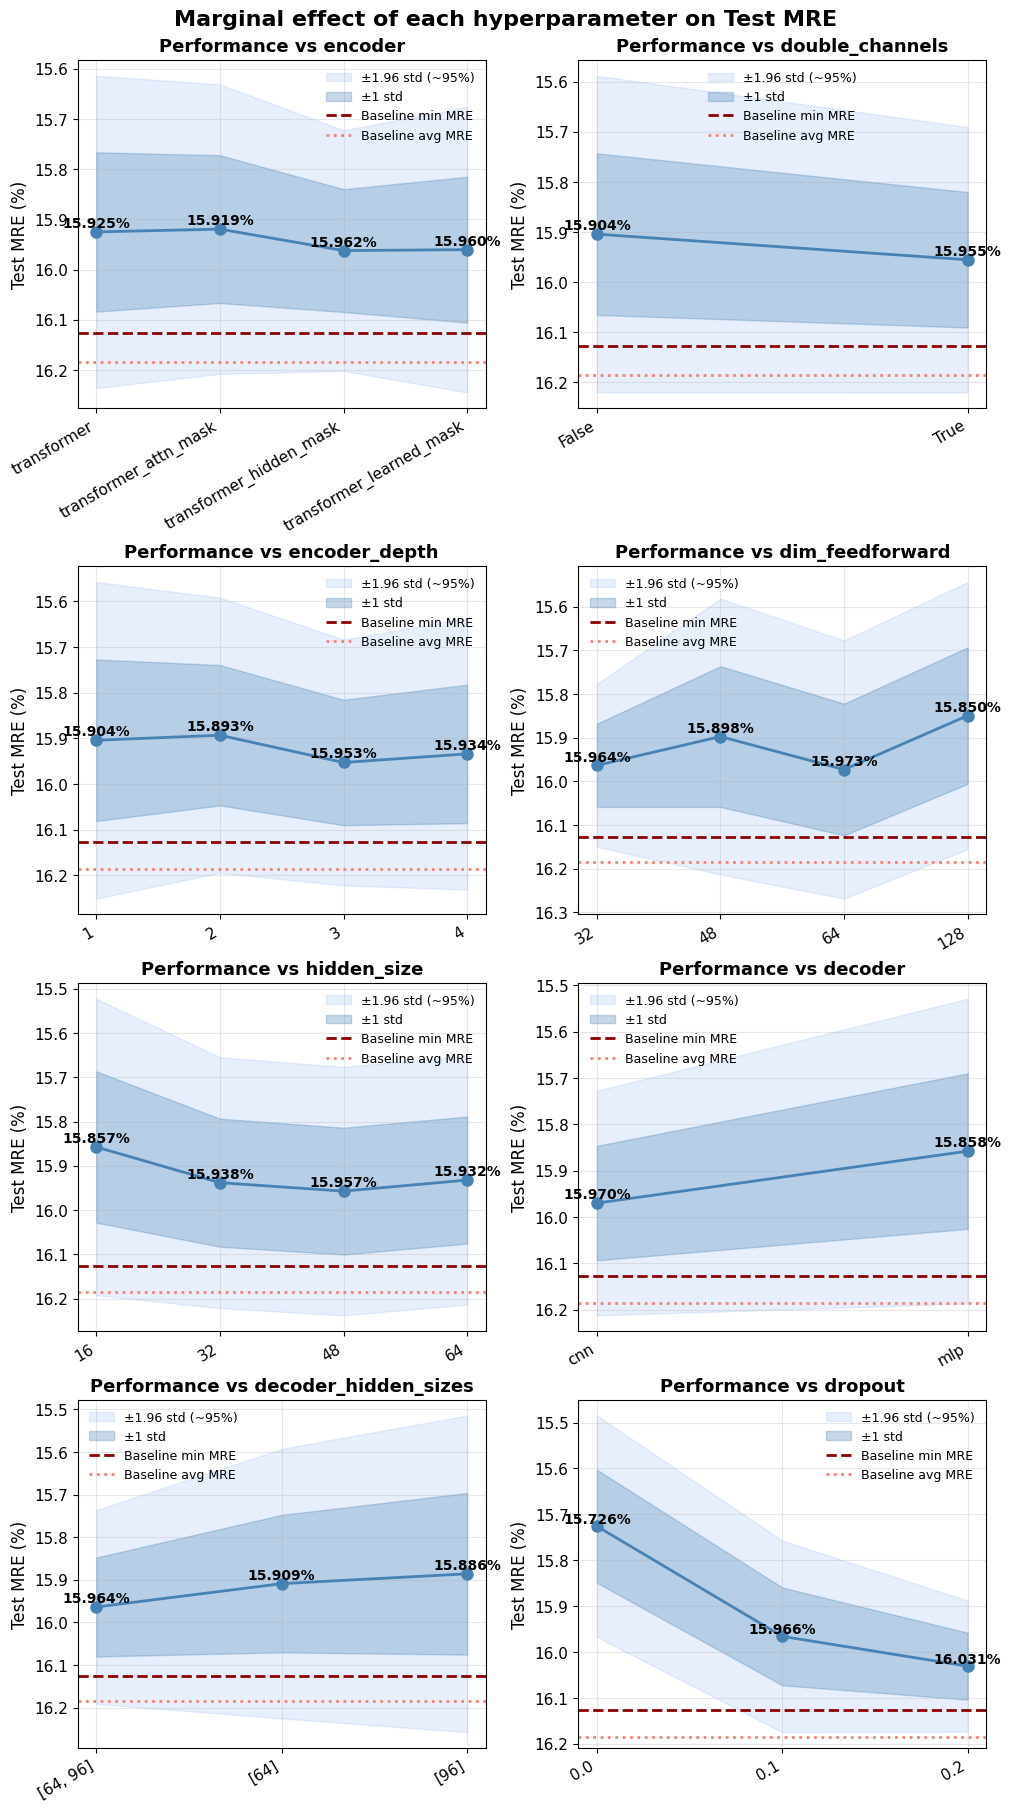